<a href="https://www.kaggle.com/code/anselmelvis/gemma-food-classification-ipynb?scriptVersionId=365544899" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [ ]:
%pip install -q -U "transformers>=4.53.0" \
    accelerate datasets huggingface_hub \
    pillow sentencepiece

In [ ]:
%pip install -q "pyarrow>=19,<24" "pillow>=8,<13"

In [ ]:
%pip install -q --no-deps trl==1.16.0

In [ ]:
%pip install -q \
    "transformers==5.20.1" \
    "bitsandbytes==0.50.2" \
    "Pillow==12.0.0" \
    "accelerate" \
    "timm" \
    "peft" \
    "datasets"

In [ ]:
%pip install -q -U "pyarrow>=24,<27"

In [ ]:
import transformers
import datasets
import pyarrow
import PIL
import torch

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PyArrow:", pyarrow.__version__)
print("Pillow:", PIL.__version__)
print("GPU available:", torch.cuda.is_available())

In [ ]:
import torch
import transformers
import pandas
import requests

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Pandas:", pandas.__version__)
print("Requests:", requests.__version__)
print("GPU available:", torch.cuda.is_available())

In [ ]:
import torch
import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

In [ ]:
pip check

In [ ]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi, hf_hub_download

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")

api = HfApi(token=HF_TOKEN)

print("Authenticated account:", api.whoami()["name"])

In [ ]:
from transformers import AutoProcessor

model_id = "google/gemma-3n-E4B-it"

processor = AutoProcessor.from_pretrained(
    model_id,
    token=HF_TOKEN
)

print("Processor:", type(processor).__name__)

In [ ]:
from huggingface_hub import HfApi

api = HfApi(token=HF_TOKEN)

model_id = "google/gemma-3n-E4B-it"

files = api.list_repo_files(
    repo_id=model_id,
    repo_type="model"
)

print("Total files:", len(files))

for filename in files:
    if filename.endswith((".safetensors", ".bin", ".index.json")):
        print(filename)

In [ ]:
import torch

from transformers import (
    BitsAndBytesConfig,
    Gemma3nForConditionalGeneration
)

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = Gemma3nForConditionalGeneration.from_pretrained(
    model_id,
    token=HF_TOKEN,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16,
    low_cpu_mem_usage=True,
    attn_implementation="sdpa"
)

# Our previously validated inference fix
model.model.vision_tower.float()

print("Model loaded successfully.")

In [ ]:
from datasets import load_dataset
import matplotlib.pyplot as plt

test_dataset = load_dataset(
    "ethz/food101",
    split="validation",
    streaming=True,
)

sample = next(iter(test_dataset))

image = sample["image"].convert("RGB")
label_names = test_dataset.features["label"].names
food_label = label_names[sample["label"]]

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.axis("off")
plt.title(f"Ground truth: {food_label}")
plt.show()

print("Image size:", image.size)
print("Ground truth:", food_label)

In [ ]:
import torch

model.eval()

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": (
                    "Identify the food shown in this image. "
                    "Reply with only the name of the dish."
                ),
            },
        ],
    }
]

inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
)

inputs = {
    key: value.to("cuda:0") if isinstance(value, torch.Tensor) else value
    for key, value in inputs.items()
}

with torch.inference_mode():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=30,
        do_sample=False,
    )

new_tokens = output_ids[
    0, inputs["input_ids"].shape[1]:
]

prediction = processor.tokenizer.decode(
    new_tokens,
    skip_special_tokens=True,
).strip()

print("Gemma prediction:", prediction)
print("Ground truth:", food_label)

In [ ]:
from datasets import load_dataset

eval_dataset = load_dataset(
    "ethz/food101",
    split="validation",
    streaming=True,
)

# Shuffle the streaming dataset
eval_dataset = eval_dataset.shuffle(
    seed=42,
    buffer_size=1000,
)

eval_samples = []
seen_labels = set()

for sample in eval_dataset:
    label = sample["label"]

    if label not in seen_labels:
        eval_samples.append(sample)
        seen_labels.add(label)

    if len(eval_samples) == 10:
        break

print("Collected:", len(eval_samples), "images")

for i, sample in enumerate(eval_samples):
    print(
        i + 1,
        label_names[sample["label"]]
    )

In [ ]:
import torch
import pandas as pd

results = []
model.eval()

for i, sample in enumerate(eval_samples):

    image = sample["image"].convert("RGB")
    ground_truth = label_names[sample["label"]]

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {
                    "type": "text",
                    "text": (
                        "Identify the food shown in this image. "
                        "Reply with only the name of the dish."
                    ),
                },
            ],
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs = {
        key: value.to("cuda:0")
        if isinstance(value, torch.Tensor)
        else value
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=False,
        )

    new_tokens = output_ids[
        0, inputs["input_ids"].shape[1]:
    ]

    prediction = processor.tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()

    correct = (
        prediction.lower().replace("_", " ")
        == ground_truth.lower().replace("_", " ")
    )

    results.append({
        "ground_truth": ground_truth,
        "prediction": prediction,
        "correct": correct,
    })

    print(
        f"{i + 1}/{len(eval_samples)} | "
        f"Actual: {ground_truth} | "
        f"Predicted: {prediction} | "
        f"Correct: {correct}"
    )

results_df = pd.DataFrame(results)

accuracy = results_df["correct"].mean()

print(f"\nAccuracy: {accuracy:.2%}")

display(results_df)

In [ ]:
food_categories = [
    label.replace("_", " ")
    for label in label_names
]

category_text = ", ".join(food_categories)

print("Number of categories:", len(food_categories))
print("First five:", food_categories[:5])

In [ ]:
classification_prompt = f"""
Identify the main dish shown in this image.

Choose exactly one dish from the following list:

{category_text}

Return only the selected dish name.
Do not provide explanations or additional descriptions.
"""

import torch
import pandas as pd

closed_set_results = []
valid_categories = {name.lower().strip() for name in food_categories}

model.eval()

for i, sample in enumerate(eval_samples):
    image = sample["image"].convert("RGB")
    ground_truth = label_names[sample["label"]].replace("_", " ")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": classification_prompt},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs = {
        key: value.to("cuda:0") if isinstance(value, torch.Tensor) else value
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=False,
        )

    new_tokens = output_ids[0, inputs["input_ids"].shape[1]:]

    prediction = processor.tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()

    normalized_prediction = prediction.lower().strip().rstrip(".")
    normalized_truth = ground_truth.lower().strip()

    correct = normalized_prediction == normalized_truth

    closed_set_results.append({
        "ground_truth": ground_truth,
        "prediction": prediction,
        "correct": correct,
        "valid_category": normalized_prediction in valid_categories,
    })

    print(
        f"{i + 1}/{len(eval_samples)} | "
        f"Actual: {ground_truth} | "
        f"Predicted: {prediction} | "
        f"Correct: {correct}"
    )

closed_set_df = pd.DataFrame(closed_set_results)

print(f"\nClosed-set accuracy: {closed_set_df['correct'].mean():.2%}")
print(f"Valid category rate: {closed_set_df['valid_category'].mean():.2%}")

display(closed_set_df)

In [ ]:
def normalize_label(text):
    return (
        str(text)
        .lower()
        .replace("_", " ")
        .strip()
        .rstrip(".")
    )

open_df = results_df.copy()
closed_df = closed_set_df.copy()

open_df.to_csv("/kaggle/working/gemma_open_ended_results.csv", index=False)
closed_df.to_csv("/kaggle/working/gemma_closed_set_results.csv", index=False)

open_accuracy = (
    open_df["prediction"].map(normalize_label)
    == open_df["ground_truth"].map(normalize_label)
).mean()

closed_accuracy = (
    closed_df["prediction"].map(normalize_label)
    == closed_df["ground_truth"].map(normalize_label)
).mean()

print(f"Open-ended accuracy: {open_accuracy:.2%}")
print(f"Closed-set accuracy: {closed_accuracy:.2%}")
print("Baseline results saved.")

In [ ]:
from datasets import load_dataset
from collections import defaultdict

train_dataset = load_dataset(
    "ethz/food101",
    split="train"
)

indices_by_class = defaultdict(list)

for index, label in enumerate(train_dataset["label"]):
    if len(indices_by_class[label]) < 5:
        indices_by_class[label].append(index)

selected_indices = [
    index
    for label in range(101)
    for index in indices_by_class[label]
]

balanced_train = (
    train_dataset
    .select(selected_indices)
    .shuffle(seed=42)
)

print("Training examples:", len(balanced_train))
print("Number of categories:", len(indices_by_class))

assert len(balanced_train) == 505

In [ ]:
from datasets import Dataset

def format_food_example(sample):
    image = sample["image"].convert("RGB")

    food_name = (
        label_names[sample["label"]]
        .replace("_", " ")
    )

    return {
        "images": [image],
        "messages": [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {
                        "type": "text",
                        "text": classification_prompt
                    }
                ]
            },
            {
                "role": "assistant",
                "content": [
                    {
                        "type": "text",
                        "text": food_name
                    }
                ]
            }
        ]
    }

formatted_dataset = Dataset.from_list([
    format_food_example(sample)
    for sample in balanced_train
])

print("Formatted examples:", len(formatted_dataset))
print("Columns:", formatted_dataset.column_names)
print(
    "Example label:",
    formatted_dataset[0]["messages"][1]["content"][0]["text"]
)

In [ ]:
from peft import LoraConfig, get_peft_model

# Freeze all pretrained parameters.
for parameter in model.parameters():
    parameter.requires_grad = False

attention_targets = [
    name
    for name, module in model.named_modules()
    if name.startswith("model.language_model.layers.")
    and name.split(".")[-1] in {
        "q_proj", "k_proj", "v_proj", "o_proj"
    }
]

print("Attention modules:", len(attention_targets))

assert len(attention_targets) == 110, (
    f"Unexpected module count: {len(attention_targets)}"
)

peft_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=attention_targets,
    task_type="CAUSAL_LM"
)

model = get_peft_model(
    model,
    peft_config
)

model.print_trainable_parameters()

In [ ]:
model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    }
)

model.config.use_cache = False

quantized_altup_modules = [
    (name, module)
    for name, module in model.named_modules()
    if hasattr(module, "prediction_coefs")
    and module.prediction_coefs.weight.dtype == torch.uint8
]

print(
    "Quantized AltUp modules:",
    len(quantized_altup_modules)
)

for name, module in quantized_altup_modules:
    module.eval()
    module.train = lambda mode=True, m=module: m

print("Gradient checkpointing configured.")
print("AltUp compatibility workaround applied.")

In [ ]:
import torch

trainable_params = [
    (name, parameter)
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
]

print(
    "Trainable tensors:",
    len(trainable_params)
)

print(
    "Trainable parameters:",
    sum(p.numel() for _, p in trainable_params)
)

print(
    "Trainable dtypes:",
    {str(p.dtype) for _, p in trainable_params}
)

print(
    "All trainable weights finite:",
    all(
        torch.isfinite(p).all().item()
        for _, p in trainable_params
    )
)

free, total = torch.cuda.mem_get_info()

print(
    f"Free GPU memory: {free / 1024**3:.2f} GiB"
)

In [ ]:
from trl import SFTConfig, SFTTrainer

training_args = SFTConfig(
    output_dir="/kaggle/working/gemma_food_results",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=1,
    learning_rate=2e-5,
    max_steps=1,
    logging_steps=1,
    save_strategy="no",
    fp16=False,
    bf16=False,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    remove_unused_columns=False,
    report_to="none",
    dataloader_num_workers=0,
)

# Prevent Trainer from attempting DataParallel on both T4 GPUs.
training_args._n_gpu = 1

trainer = SFTTrainer(
    model=model,
    train_dataset=formatted_dataset,
    processing_class=processor,
    args=training_args,
)

print("Trainer initialized successfully.")

In [ ]:
import torch

original_collator = trainer.data_collator

assistant_marker = processor.tokenizer.encode(
    "<start_of_turn>model",
    add_special_tokens=False
)

def food_classification_collator(examples):
    batch = original_collator(examples)

    input_ids = batch["input_ids"]
    labels = torch.full_like(input_ids, -100)

    for row in range(input_ids.shape[0]):
        ids = input_ids[row].tolist()

        positions = [
            i
            for i in range(len(ids) - len(assistant_marker) + 1)
            if ids[i:i + len(assistant_marker)] == assistant_marker
        ]

        if len(positions) != 1:
            raise ValueError(
                f"Expected one assistant marker, found {len(positions)}"
            )

        start = positions[0] + len(assistant_marker)

        while start < len(ids):
            token_text = processor.tokenizer.decode([ids[start]])
            if token_text.strip():
                break
            start += 1

        for j in range(start, len(ids)):
            if batch["attention_mask"][row, j] == 1:
                labels[row, j] = input_ids[row, j]

    batch["labels"] = labels
    return batch

trainer.data_collator = food_classification_collator

print("Assistant-only collator configured.")

In [ ]:
import torch

model = trainer.model

print("Training examples:", len(formatted_dataset))
print("Learning rate:", training_args.learning_rate)
print("Collator configured:",
      trainer.data_collator.__name__)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

assert len(formatted_dataset) == 505
assert training_args.learning_rate == 2e-5
assert trainer.data_collator.__name__ == "food_classification_collator"

print("Environment ready.")

In [ ]:
import torch
import time
import pandas as pd

model.train()
model.config.use_cache = False

assert all(
    not module.training
    for _, module in quantized_altup_modules
)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=2e-5
)

trainable_params = [
    p for p in model.parameters() if p.requires_grad
]

train_loader = trainer.get_train_dataloader()

num_steps = len(train_loader)
history = []

print("Planned training steps:", num_steps)

start_time = time.time()

for step, batch in enumerate(train_loader, start=1):

    batch = {
        k: v.to("cuda:0")
        for k, v in batch.items()
        if isinstance(v, torch.Tensor)
    }

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(device_type="cuda", enabled=False):
        outputs = model(**batch)
        loss = outputs.loss

    if not torch.isfinite(loss).item():
        raise RuntimeError(f"Non-finite loss at step {step}")

    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        trainable_params,
        max_norm=1.0,
        error_if_nonfinite=True
    )

    optimizer.step()

    if not all(torch.isfinite(p).all().item() for p in trainable_params):
        raise RuntimeError(f"Non-finite weights at step {step}")

    history.append({
        "step": step,
        "loss": float(loss.item()),
        "gradient_norm": float(grad_norm.item())
    })

    if step == 1 or step % 25 == 0:
        elapsed = time.time() - start_time

        print(
            f"Step {step}/{num_steps} | "
            f"Loss: {loss.item():.4f} | "
            f"Grad norm: {grad_norm.item():.4f} | "
            f"Elapsed: {elapsed/60:.1f} min"
        )

    if step % 100 == 0:
        checkpoint_dir = (
            f"/kaggle/working/gemma_food_lr2e5_step{step}"
        )

        model.save_pretrained(
            checkpoint_dir,
            safe_serialization=True
        )

        print("Checkpoint saved:", checkpoint_dir)

    del outputs, loss, batch

final_dir = "/kaggle/working/gemma_food_lr2e5_final"

model.save_pretrained(final_dir, safe_serialization=True)
processor.save_pretrained(final_dir)

pd.DataFrame(history).to_csv(
    "/kaggle/working/gemma_food_lr2e5_history.csv",
    index=False
)

print("\nTraining complete.")
print("Final checkpoint:", final_dir)

In [ ]:
import os
import pandas as pd

checkpoint = "/kaggle/working/gemma_food_lr2e5_final"
history_path = "/kaggle/working/gemma_food_lr2e5_history.csv"

print("Adapter weights:", os.path.isfile(f"{checkpoint}/adapter_model.safetensors"))
print("Adapter config:", os.path.isfile(f"{checkpoint}/adapter_config.json"))

history_df = pd.read_csv(history_path)

print("Training updates:", len(history_df))
print("Last step:", history_df["step"].iloc[-1])
print("Final recorded loss:", history_df["loss"].iloc[-1])

In [ ]:
print("Model type:", type(model).__name__)
print("Model training mode:", model.training)
print("Adapter enabled:", not model.disable_adapters)
print("Processor available:", processor is not None)
print("Validation variables:")

for name in [
    "validation_examples",
    "validation_samples",
    "val_samples",
    "normalize_label"
]:
    print(name, name in globals())

In [ ]:
from datasets import load_dataset

validation_stream = load_dataset(
    "ethz/food101",
    split="validation",
    streaming=True
).shuffle(seed=123, buffer_size=1000)

evaluation_samples = []
seen_labels = set()

for example in validation_stream:
    if example["label"] in seen_labels:
        continue

    evaluation_samples.append(example)
    seen_labels.add(example["label"])

    if len(evaluation_samples) == 50:
        break

assert len(evaluation_samples) == 50

print("Validation images:", len(evaluation_samples))
print("Unique food categories:", len(seen_labels))

In [ ]:
import torch
import pandas as pd
import time

# ==========================================
# 1. PREPARE MODEL FOR EVALUATION
# ==========================================

model.eval()

# Enable the attached LoRA layers.
# This is the PEFT-compatible method.
model.base_model.enable_adapter_layers()

print("Active adapter:", model.active_adapter)
print("Validation images:", len(evaluation_samples))

assert len(evaluation_samples) == 50


# ==========================================
# 2. PREDICTION FUNCTION
# ==========================================

def predict_food(image):

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image.convert("RGB")
                },
                {
                    "type": "text",
                    "text": classification_prompt
                }
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        k: v.to("cuda:0") if isinstance(v, torch.Tensor) else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            enabled=False
        ):
            output = model.generate(
                **inputs,
                max_new_tokens=20,
                do_sample=False
            )

    generated_tokens = output[0][
        inputs["input_ids"].shape[1]:
    ]

    prediction = processor.tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    return prediction


# ==========================================
# 3. EVALUATE BOTH MODELS
# ==========================================

results = []
start_time = time.time()

for index, example in enumerate(
    evaluation_samples,
    start=1
):

    image = example["image"]

    true_label = label_names[
        example["label"]
    ].replace("_", " ")

    # Original Gemma 3n (LoRA disabled)
    with model.disable_adapter():
        baseline_prediction = predict_food(image)

    # Fine-tuned Gemma 3n (LoRA enabled)
    tuned_prediction = predict_food(image)

    baseline_correct = (
        normalize_label(baseline_prediction)
        == normalize_label(true_label)
    )

    tuned_correct = (
        normalize_label(tuned_prediction)
        == normalize_label(true_label)
    )

    results.append({
        "image": index,
        "true_label": true_label,
        "baseline_prediction": baseline_prediction,
        "tuned_prediction": tuned_prediction,
        "baseline_correct": baseline_correct,
        "tuned_correct": tuned_correct
    })

    if index % 10 == 0:

        elapsed = (time.time() - start_time) / 60

        print(
            f"Evaluated {index}/50 images | "
            f"Elapsed: {elapsed:.1f} min"
        )


# ==========================================
# 4. CALCULATE ACCURACY
# ==========================================

comparison_df = pd.DataFrame(results)

baseline_correct_count = int(
    comparison_df["baseline_correct"].sum()
)

tuned_correct_count = int(
    comparison_df["tuned_correct"].sum()
)

baseline_accuracy = (
    baseline_correct_count / len(comparison_df)
)

tuned_accuracy = (
    tuned_correct_count / len(comparison_df)
)

errors_corrected = int((
    (~comparison_df["baseline_correct"]) &
    comparison_df["tuned_correct"]
).sum())

new_errors = int((
    comparison_df["baseline_correct"] &
    (~comparison_df["tuned_correct"])
).sum())


# ==========================================
# 5. DISPLAY RESULTS
# ==========================================

print("\n" + "=" * 50)
print("GEMMA 3N FOOD-101 EVALUATION RESULTS")
print("=" * 50)

print(
    f"Original Gemma 3n: "
    f"{baseline_correct_count}/50 "
    f"({baseline_accuracy:.1%})"
)

print(
    f"505-step LoRA:     "
    f"{tuned_correct_count}/50 "
    f"({tuned_accuracy:.1%})"
)

print(
    f"Accuracy change:   "
    f"{(tuned_accuracy - baseline_accuracy):+.1%}"
)

print(f"Errors corrected:  {errors_corrected}")
print(f"New errors:        {new_errors}")

print("=" * 50)


# ==========================================
# 6. SAVE EVALUATION RESULTS
# ==========================================

output_path = (
    "/kaggle/working/"
    "gemma_505_step_evaluation.csv"
)

comparison_df.to_csv(
    output_path,
    index=False
)

print("\nEvaluation saved to:", output_path)

# Leave LoRA enabled after evaluation
model.base_model.enable_adapter_layers()

print("Evaluation complete.")

In [ ]:
changed = comparison_df[
    comparison_df["baseline_correct"]
    != comparison_df["tuned_correct"]
].copy()

changed["outcome"] = changed.apply(
    lambda row: (
        "CORRECTED"
        if row["tuned_correct"]
        else "NEW ERROR"
    ),
    axis=1
)

display(
    changed[
        [
            "image",
            "true_label",
            "baseline_prediction",
            "tuned_prediction",
            "outcome"
        ]
    ]
)

In [ ]:
from datasets import load_dataset
from collections import Counter

validation_stream = load_dataset(
    "ethz/food101",
    split="validation",
    streaming=True
).shuffle(seed=456, buffer_size=1000)

counts = Counter()
large_eval_samples = []

for example in validation_stream:
    label = example["label"]

    if counts[label] >= 3:
        continue

    large_eval_samples.append(example)
    counts[label] += 1

    if len(large_eval_samples) == 303:
        break

assert len(large_eval_samples) == 303
assert len(counts) == 101
assert all(count == 3 for count in counts.values())

print("Validation images:", len(large_eval_samples))
print("Categories represented:", len(counts))
print("Images per category:", set(counts.values()))

In [ ]:
import torch
import pandas as pd
import time

model.eval()
model.base_model.enable_adapter_layers()

results_303 = []
start_time = time.time()

for index, example in enumerate(large_eval_samples, start=1):

    image = example["image"]
    true_label = label_names[example["label"]].replace("_", " ")

    # Baseline: original Gemma 3n
    with model.disable_adapter():
        baseline_prediction = predict_food(image)

    # Fine-tuned: Gemma 3n with LoRA
    tuned_prediction = predict_food(image)

    baseline_correct = (
        normalize_label(baseline_prediction)
        == normalize_label(true_label)
    )

    tuned_correct = (
        normalize_label(tuned_prediction)
        == normalize_label(true_label)
    )

    results_303.append({
        "image": index,
        "category": true_label,
        "baseline_prediction": baseline_prediction,
        "tuned_prediction": tuned_prediction,
        "baseline_correct": baseline_correct,
        "tuned_correct": tuned_correct
    })

    if index % 25 == 0 or index == 303:
        elapsed = (time.time() - start_time) / 60
        print(
            f"Evaluated {index}/303 | "
            f"Elapsed: {elapsed:.1f} min"
        )

# Calculate results
df_303 = pd.DataFrame(results_303)

baseline_count = int(df_303["baseline_correct"].sum())
tuned_count = int(df_303["tuned_correct"].sum())

baseline_accuracy = baseline_count / 303
tuned_accuracy = tuned_count / 303

corrected = int((
    (~df_303["baseline_correct"]) &
    df_303["tuned_correct"]
).sum())

new_errors = int((
    df_303["baseline_correct"] &
    (~df_303["tuned_correct"])
).sum())

print("\n" + "=" * 55)
print("GEMMA 3N — 303-IMAGE FOOD-101 EVALUATION")
print("=" * 55)

print(f"Original Gemma 3n: {baseline_count}/303 ({baseline_accuracy:.2%})")
print(f"505-step LoRA:     {tuned_count}/303 ({tuned_accuracy:.2%})")
print(f"Accuracy change:   {(tuned_accuracy - baseline_accuracy):+.2%}")
print(f"Errors corrected:  {corrected}")
print(f"New errors:        {new_errors}")

# Save results
output_path = "/kaggle/working/gemma_303_image_evaluation.csv"
df_303.to_csv(output_path, index=False)

model.base_model.enable_adapter_layers()

print("\nEvaluation saved:", output_path)
print("Evaluation complete.")

In [ ]:
import os
import json
import shutil

working = "/kaggle/working"

report = {
    "experiment": "Gemma 3n E4B Food-101 QLoRA Fine-Tuning",
    "base_model": "google/gemma-3n-E4B-it",
    "dataset": "ethz/food101",
    "training": {
        "examples": 505,
        "categories": 101,
        "steps": 505,
        "learning_rate": 2e-5,
        "lora_rank": 8,
        "lora_alpha": 16,
        "trainable_parameters": 3112960
    },
    "evaluation": {
        "validation_examples": 303,
        "categories": 101,
        "baseline_correct": 228,
        "fine_tuned_correct": 249,
        "baseline_accuracy": 228 / 303,
        "fine_tuned_accuracy": 249 / 303,
        "accuracy_improvement_percentage_points": (
            (249 - 228) / 303 * 100
        ),
        "errors_corrected": 31,
        "new_errors": 10
    }
}

report_path = os.path.join(
    working,
    "gemma_food_final_report.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

package_dir = os.path.join(
    working,
    "gemma_food_submission"
)

os.makedirs(package_dir, exist_ok=True)

shutil.copytree(
    os.path.join(working, "gemma_food_lr2e5_final"),
    os.path.join(package_dir, "adapter"),
    dirs_exist_ok=True
)

for filename in [
    "gemma_food_lr2e5_history.csv",
    "gemma_505_step_evaluation.csv",
    "gemma_303_image_evaluation.csv",
    "gemma_food_final_report.json"
]:
    source = os.path.join(working, filename)

    if os.path.isfile(source):
        shutil.copy2(source, package_dir)
    else:
        print("Missing:", filename)

archive_path = shutil.make_archive(
    os.path.join(working, "gemma_food_submission"),
    "zip",
    package_dir
)

print("Package created:", archive_path)
print(
    "Package size:",
    round(os.path.getsize(archive_path) / 1024**2, 2),
    "MB"
)

In [ ]:
%pip install -q "transformers>=4.53.0" accelerate peft bitsandbytes sentencepiece

In [ ]:
from PIL import Image
from IPython.display import display

test_image_path = "/kaggle/input/datasets/anselmelvis/test-image/test_food_item.jpg"

test_image = Image.open(test_image_path).convert("RGB")

print("Our test image:")
display(test_image)

model.eval()
model.base_model.enable_adapter_layers()

prediction = predict_food(test_image)

print("\n" + "=" * 45)
print("GEMMA 3N — NIGERIAN FOOD INFERENCE")
print("=" * 45)
print("Actual dish: Egusi soup with pounded yam")
print("Model prediction:", prediction)
print("=" * 45)

In [ ]:
batch = next(iter(trainer.get_train_dataloader()))

print("Batch keys:", list(batch.keys()))
print("Input shape:", tuple(batch["input_ids"].shape))
print("Supervised tokens:", (batch["labels"] != -100).sum().item())

assert (batch["labels"] != -100).sum().item() > 0

batch = {
    key: value.to("cuda:0")
    for key, value in batch.items()
    if isinstance(value, torch.Tensor)
}

assert torch.isfinite(batch["pixel_values"]).all().item()

print("Batch validation passed.")

In [ ]:
model = trainer.model

model.train()
model.zero_grad(set_to_none=True)

# Confirm the quantized AltUp modules remain in eval mode.
assert all(
    not module.training
    for _, module in quantized_altup_modules
), "Quantized AltUp module entered training mode."

with torch.autocast(device_type="cuda", enabled=False):
    outputs = model(**batch)

loss = outputs.loss

print("Training loss:", loss.item())
print("Loss finite:", torch.isfinite(loss).item())

assert torch.isfinite(loss).item(), (
    "Non-finite loss. Do not run backward or optimizer step."
)

In [ ]:
# Compute gradients for the existing finite loss.
loss.backward()

gradient_report = []

for name, parameter in model.named_parameters():
    if not parameter.requires_grad:
        continue

    if parameter.grad is None:
        continue

    gradient_report.append({
        "name": name,
        "finite": bool(torch.isfinite(parameter.grad).all().item()),
        "norm": float(parameter.grad.float().norm().item()),
    })

nonfinite_gradients = [
    item for item in gradient_report
    if not item["finite"]
]

print("Parameters with gradients:", len(gradient_report))
print("Non-finite gradient tensors:", len(nonfinite_gradients))

print("First five gradient norms:")
for item in gradient_report[:5]:
    print(item["name"], item["norm"])

assert len(gradient_report) > 0, "No trainable gradients found."
assert not nonfinite_gradients, (
    "Non-finite gradients detected. Do not update weights."
)

print("Backward pass validated.")

In [ ]:
from torch.optim import AdamW

optimizer = AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4
)

# Clip gradients before updating.
grad_norm = torch.nn.utils.clip_grad_norm_(
    [p for p in model.parameters() if p.requires_grad],
    max_norm=1.0,
    error_if_nonfinite=True
)

print("Gradient norm:", grad_norm.item())

optimizer.step()

# Check that adapter weights remain finite.
nonfinite_weights = [
    name
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
    and not torch.isfinite(parameter).all().item()
]

assert not nonfinite_weights, (
    f"Invalid adapter weights: {nonfinite_weights[:5]}"
)

print("First optimizer update completed successfully.")
print("All trainable weights remain finite.")

optimizer.zero_grad(set_to_none=True)

In [ ]:
import os

checkpoint_dir = "/kaggle/working/gemma_food_lora_step1"

os.makedirs(checkpoint_dir, exist_ok=True)

model.save_pretrained(
    checkpoint_dir,
    safe_serialization=True
)

processor.save_pretrained(checkpoint_dir)

print("Checkpoint saved:", checkpoint_dir)
print("Files:", os.listdir(checkpoint_dir))

In [ ]:
import torch
import gc
import time
import math

model.train()
model.config.use_cache = False

# Reuse the optimizer from our successful first step.
assert optimizer is not None

# Confirm AltUp modules remain in evaluation mode.
assert all(
    not module.training
    for _, module in quantized_altup_modules
)

train_loader = trainer.get_train_dataloader()

num_steps = 50
save_every = 10

training_history = []

start_time = time.time()

for step, batch in enumerate(train_loader, start=1):

    if step > num_steps:
        break

    batch = {
        key: value.to("cuda:0")
        for key, value in batch.items()
        if isinstance(value, torch.Tensor)
    }

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(device_type="cuda", enabled=False):
        outputs = model(**batch)
        loss = outputs.loss

    if not torch.isfinite(loss).item():
        print(f"STOP: Non-finite loss at step {step}")
        break

    loss.backward()

    trainable_parameters = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    gradients_finite = all(
        p.grad is None or torch.isfinite(p.grad).all().item()
        for p in trainable_parameters
    )

    if not gradients_finite:
        print(f"STOP: Non-finite gradients at step {step}")
        optimizer.zero_grad(set_to_none=True)
        break

    grad_norm = torch.nn.utils.clip_grad_norm_(
        trainable_parameters,
        max_norm=1.0,
        error_if_nonfinite=True
    )

    optimizer.step()

    weights_finite = all(
        torch.isfinite(p).all().item()
        for p in trainable_parameters
    )

    if not weights_finite:
        print(f"STOP: Non-finite adapter weights at step {step}")
        break

    loss_value = float(loss.item())

    training_history.append({
        "step": step,
        "loss": loss_value,
        "gradient_norm": float(grad_norm.item())
    })

    if step == 1 or step % 5 == 0:
        elapsed = time.time() - start_time

        print(
            f"Step {step}/{num_steps} | "
            f"Loss: {loss_value:.4f} | "
            f"Grad norm: {grad_norm.item():.4f} | "
            f"Elapsed: {elapsed:.1f}s"
        )

    if step % save_every == 0:
        save_dir = (
            f"/kaggle/working/gemma_food_lora_step{step + 1}"
        )

        model.save_pretrained(
            save_dir,
            safe_serialization=True
        )

        print("Checkpoint saved:", save_dir)

    del outputs, loss, batch

    # Stop automatically at 50 steps.
    if step == num_steps:
        break

print("\nCompleted additional steps:", len(training_history))

In [ ]:
import pandas as pd

final_dir = "/kaggle/working/gemma_food_lora_final"

model.save_pretrained(
    final_dir,
    safe_serialization=True
)

processor.save_pretrained(final_dir)

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    "/kaggle/working/gemma_food_training_history.csv",
    index=False
)

print("Final adapter saved:", final_dir)

if not history_df.empty:
    print("First loss:", history_df["loss"].iloc[0])
    print("Last loss:", history_df["loss"].iloc[-1])
    print("Lowest loss:", history_df["loss"].min())

In [ ]:
import torch
import pandas as pd

model.eval()
finetuned_results = []

for i, sample in enumerate(eval_samples):
    image = sample["image"].convert("RGB")
    ground_truth = label_names[sample["label"]].replace("_", " ")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": classification_prompt},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs = {
        key: value.to("cuda:0") if isinstance(value, torch.Tensor) else value
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=False,
        )

    new_tokens = output_ids[0, inputs["input_ids"].shape[1]:]

    prediction = processor.tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()

    correct = (
        normalize_label(prediction)
        == normalize_label(ground_truth)
    )

    finetuned_results.append({
        "ground_truth": ground_truth,
        "prediction": prediction,
        "correct": correct,
    })

    print(
        f"{i + 1}/10 | "
        f"Actual: {ground_truth} | "
        f"Predicted: {prediction} | "
        f"Correct: {correct}"
    )

finetuned_df = pd.DataFrame(finetuned_results)

print(
    f"\nFine-tuned closed-set accuracy: "
    f"{finetuned_df['correct'].mean():.2%}"
)

finetuned_df.to_csv(
    "/kaggle/working/gemma_finetuned_closed_set_results.csv",
    index=False
)

display(finetuned_df)

In [ ]:
baseline_accuracy = closed_df["correct"].mean()
finetuned_accuracy = finetuned_df["correct"].mean()

comparison_df = pd.DataFrame({
    "Model": [
        "Gemma 3n — pretrained",
        "Gemma 3n — fine-tuned (51 updates)"
    ],
    "Closed-set accuracy": [
        baseline_accuracy,
        finetuned_accuracy
    ]
})

display(comparison_df)

print(f"Baseline: {baseline_accuracy:.2%}")
print(f"Fine-tuned: {finetuned_accuracy:.2%}")
print(
    f"Change: "
    f"{(finetuned_accuracy - baseline_accuracy) * 100:+.1f} percentage points"
)

In [ ]:
import torch
import pandas as pd
from datasets import load_dataset

# Prepare 50 held-out images.
validation_stream = load_dataset(
    "ethz/food101",
    split="validation",
    streaming=True
).shuffle(seed=123, buffer_size=1000)

validation_samples = []
seen_labels = set()

for sample in validation_stream:
    if sample["label"] not in seen_labels:
        validation_samples.append(sample)
        seen_labels.add(sample["label"])

    if len(validation_samples) == 50:
        break

print("Validation images:", len(validation_samples))


def predict_food(sample, use_adapter=True):
    image = sample["image"].convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": classification_prompt},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to("cuda:0")
        if isinstance(value, torch.Tensor)
        else value
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=False
        )

    new_tokens = output_ids[
        0, inputs["input_ids"].shape[1]:
    ]

    return processor.tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()


model.eval()
comparison_results = []

for i, sample in enumerate(validation_samples):
    ground_truth = label_names[sample["label"]].replace("_", " ")

    with model.disable_adapter():
        pretrained_prediction = predict_food(sample)

    finetuned_prediction = predict_food(sample)

    pretrained_correct = (
        normalize_label(pretrained_prediction)
        == normalize_label(ground_truth)
    )

    finetuned_correct = (
        normalize_label(finetuned_prediction)
        == normalize_label(ground_truth)
    )

    comparison_results.append({
        "ground_truth": ground_truth,
        "pretrained_prediction": pretrained_prediction,
        "finetuned_prediction": finetuned_prediction,
        "pretrained_correct": pretrained_correct,
        "finetuned_correct": finetuned_correct
    })

    print(
        f"{i + 1}/50 | "
        f"Pretrained: {pretrained_correct} | "
        f"Fine-tuned: {finetuned_correct}"
    )

comparison_50_df = pd.DataFrame(comparison_results)

comparison_50_df.to_csv(
    "/kaggle/working/gemma_50_image_comparison.csv",
    index=False
)

print("\nPretrained accuracy:",
      f"{comparison_50_df['pretrained_correct'].mean():.2%}")

print("Fine-tuned accuracy:",
      f"{comparison_50_df['finetuned_correct'].mean():.2%}")

In [ ]:
import json
import os
import pandas as pd

report = {
    "model": "google/gemma-3n-E4B-it",
    "dataset": "ethz/food101",
    "num_classes": 101,
    "training_examples": 505,
    "training_examples_per_class": 5,
    "fine_tuning_method": "4-bit base model + LoRA",
    "trainable_parameters": 3112960,
    "optimizer_updates": 51,
    "learning_rate": 1e-4,
    "evaluation_examples": 50,
    "pretrained_accuracy": 0.80,
    "finetuned_accuracy": 0.80,
    "accuracy_change_percentage_points": 0.0,
    "conclusion": (
        "Fine-tuning completed successfully, but did not improve "
        "overall accuracy on the 50-image held-out evaluation."
    )
}

report_path = "/kaggle/working/gemma_food_experiment_report.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("Experiment report saved:", report_path)
print("Final adapter:", "/kaggle/working/gemma_food_lora_final")
print("Comparison CSV:", "/kaggle/working/gemma_50_image_comparison.csv")

In [ ]:
import shutil
import os

backup_dir = "/kaggle/working/gemma_food_backup"

os.makedirs(backup_dir, exist_ok=True)

shutil.copytree(
    "/kaggle/working/gemma_food_lora_final",
    f"{backup_dir}/gemma_food_lora_final",
    dirs_exist_ok=True
)

for filename in [
    "gemma_food_experiment_report.json",
    "gemma_50_image_comparison.csv",
    "gemma_food_training_history.csv",
]:
    source = f"/kaggle/working/{filename}"

    if os.path.exists(source):
        shutil.copy2(source, backup_dir)

zip_path = shutil.make_archive(
    "/kaggle/working/gemma_food_backup",
    "zip",
    backup_dir
)

print("Backup created:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / 1024**2, 2), "MB")

In [ ]:
import os
import torch

print("CUDA available:", torch.cuda.is_available())

print(
    "Model loaded:",
    "model" in globals()
)

print(
    "Processor loaded:",
    "processor" in globals()
)

print(
    "Trainer available:",
    "trainer" in globals()
)

print(
    "Training dataset available:",
    "formatted_dataset" in globals()
)

print(
    "Saved adapter exists:",
    os.path.exists(
        "/kaggle/working/gemma_food_lora_final/adapter_model.safetensors"
    )
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

In [ ]:
import os

for path in [
    "/kaggle/input",
    "/kaggle/working",
]:
    print(f"\n{path}")

    if os.path.exists(path):
        print(os.listdir(path)[:30])

In [ ]:
import transformers
import tokenizers
import huggingface_hub
import torch

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("PyTorch:", torch.__version__)

In [ ]:
import torch

from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Gemma3nForConditionalGeneration
)

from peft import PeftModel
from kaggle_secrets import UserSecretsClient

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")

model_id = "google/gemma-3n-E4B-it"

adapter_path = (
    "/kaggle/input/datasets/anselmelvis/"
    "gemma-food-trained-adapter/adapter"
)

# Load processor
processor = AutoProcessor.from_pretrained(
    model_id,
    token=HF_TOKEN
)

# Configure 4-bit quantization
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# Load base model
base_model = Gemma3nForConditionalGeneration.from_pretrained(
    model_id,
    token=HF_TOKEN,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True,
    attn_implementation="eager"
)

# Restore FP32 vision tower
base_model.model.vision_tower.float()

# Attach the previously trained adapter
model = PeftModel.from_pretrained(
    base_model,
    adapter_path,
    is_trainable=False
)

model.eval()

print("Gemma 3n restored successfully!")
print("Active adapter:", model.active_adapter)

In [ ]:
from safetensors import safe_open
from collections import Counter

adapter_file = adapter_path + "/adapter_model.safetensors"

with safe_open(adapter_file, framework="pt", device="cpu") as f:
    saved_keys = list(f.keys())

loaded_lora = [
    name for name, _ in model.named_parameters()
    if "lora_A" in name or "lora_B" in name
]

print("Saved LoRA tensors:", len(saved_keys))
print("Expected LoRA tensors in current model:", len(loaded_lora))

print("\nSaved attention-layer distribution:")
saved_layers = Counter()

for key in saved_keys:
    if "language_model.layers." in key:
        layer = key.split("language_model.layers.")[1].split(".")[0]
        saved_layers[layer] += 1

print(dict(sorted(saved_layers.items(), key=lambda x: int(x[0]))))

print("\nCurrent model LoRA parameters:")
model.print_trainable_parameters()

In [ ]:
from PIL import Image
from IPython.display import display

test_image_path = (
    "/kaggle/input/datasets/anselmelvis/"
    "test-image/test_food_item.jpg"
)

test_image = Image.open(test_image_path).convert("RGB")

display(test_image)

print("Image dimensions:", test_image.size)

In [ ]:
with torch.inference_mode():
    with torch.autocast(device_type="cuda", enabled=False):
        outputs = model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False
        )

generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

prediction = processor.tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
).strip()

print("Actual dish: Egusi soup with pounded yam")
print("Fine-tuned Gemma prediction:", prediction)

In [ ]:
# Original Gemma 3n prediction (LoRA disabled)

with model.disable_adapter():
    with torch.inference_mode():
        with torch.autocast(device_type="cuda", enabled=False):
            base_outputs = model.generate(
                **inputs,
                max_new_tokens=80,
                do_sample=False
            )

base_tokens = base_outputs[0][inputs["input_ids"].shape[1]:]

base_prediction = processor.tokenizer.decode(
    base_tokens,
    skip_special_tokens=True
).strip()

print("ACTUAL DISH:")
print("Egusi soup with pounded yam")

print("\nORIGINAL GEMMA PREDICTION:")
print(base_prediction)

print("\nFINE-TUNED GEMMA PREDICTION:")
print(prediction)

In [ ]:
import pandas as pd

csv_path = (
    "/kaggle/input/datasets/anselmelvis/"
    "gemma-food-trained-adapter/gemma_303_image_evaluation.csv"
)

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# Normalise food labels for fair comparison
def normalize_label(label):
    return str(label).strip().lower().replace("_", " ")

# Ground truth
y_true = df["category"].apply(normalize_label)

# Predictions from both models
y_baseline = df["baseline_prediction"].apply(normalize_label)
y_tuned = df["tuned_prediction"].apply(normalize_label)

# Calculate metrics
def evaluate_model(name, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    }

results = pd.DataFrame([
    evaluate_model("Original Gemma", y_baseline),
    evaluate_model("Fine-tuned Gemma", y_tuned)
])

display(
    results.style.format({
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}"
    })
)

print("\nFINE-TUNED MODEL CLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_tuned,
        zero_division=0
    )
)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Find categories with the most mistakes
errors = df.loc[
    y_true != y_tuned,
    "category"
].value_counts()

worst_categories = errors.head(8).index.tolist()

# Include actual labels and the predictions made for those examples
mask = y_true.isin(worst_categories)

actual = y_true[mask]
predicted = y_tuned[mask]

labels = sorted(set(actual) | set(predicted))

cm = confusion_matrix(
    actual,
    predicted,
    labels=labels
)

fig, ax = plt.subplots(figsize=(12, 10))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_cm.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Fine-tuned Gemma: Confusion Matrix for Difficult Categories")
plt.tight_layout()
plt.show()

print("Most frequently misclassified categories:")
print(errors.head(8))

In [ ]:

import time
import statistics
import torch

# 1. Prepare the image and prompt
prompt = "Classify this food item. What dish is this? Answer briefly."

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": test_image},
        {"type": "text", "text": prompt},
    ],
}]

inputs = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt",
)

# 2. Move inputs to the model's actual GPU
device = model.get_input_embeddings().weight.device
inputs = {
    k: v.to(device) if isinstance(v, torch.Tensor) else v
    for k, v in inputs.items()
}

gpu_id = device.index
model.eval()

# 3. Inference function
def run_inference():
    with torch.inference_mode():
        with torch.autocast(device_type="cuda", enabled=False):
            output = model.generate(
                **inputs,
                max_new_tokens=20,
                do_sample=False,
            )
    return output

# 4. Warm up GPU
print("Warming up GPU...")
_ = run_inference()
torch.cuda.synchronize(device)

# 5. Reset peak memory statistics
torch.cuda.reset_peak_memory_stats(device)

# 6. Benchmark five runs
latencies = []
output_tokens = []

print("Running benchmark...")

for i in range(5):
    torch.cuda.synchronize(device)
    start = time.perf_counter()

    output = run_inference()

    torch.cuda.synchronize(device)
    elapsed = time.perf_counter() - start

    generated = output.shape[1] - inputs["input_ids"].shape[1]

    latencies.append(elapsed)
    output_tokens.append(generated)

    print(
        f"Run {i+1}: {elapsed:.3f} seconds "
        f"({generated} generated tokens)"
    )

# 7. Calculate metrics
avg_latency = statistics.mean(latencies)
median_latency = statistics.median(latencies)
throughput = 1 / avg_latency

peak_vram = (
    torch.cuda.max_memory_allocated(device) / (1024**3)
)

print("\n===== INFERENCE BENCHMARK =====")
print(f"GPU: {torch.cuda.get_device_name(gpu_id)}")
print(f"Average latency: {avg_latency:.3f} seconds/image")
print(f"Median latency: {median_latency:.3f} seconds/image")
print(f"Sequential throughput: {throughput:.3f} images/second")
print(f"Peak allocated VRAM: {peak_vram:.3f} GB")
print(f"Average generated tokens: {statistics.mean(output_tokens):.1f}")

## Final Evaluation Results

### Model Performance

Evaluated on 303 Food-101 validation images across 101 categories.

| Metric | Original Gemma | Fine-tuned Gemma |
|---|---|---|
| Accuracy | 75.25% | 82.18% |
| Macro Precision | 73.14% | 83.81% |
| Macro Recall | 67.86% | 80.58% |
| Macro F1 | 67.35% | 79.87% |

**Accuracy improvement:** +6.93 percentage points.

### Inference Efficiency

The benchmark was conducted on an NVIDIA Tesla T4 GPU, using five warmed-up sequential inference runs.

- Average latency: 5.465 seconds/image
- Median latency: 5.451 seconds/image
- Sequential throughput: 0.183 images/second
- Peak allocated VRAM: 9.248 GB
- Average generated tokens: 20

### Out-of-Distribution Testing

An unseen image of Nigerian egusi soup with pounded yam was evaluated.

- **Original Gemma:** Correctly identified egusi soup with pounded yam.
- **Fine-tuned Gemma:** Incorrectly identified the soup as Ofe Akwu.

This single example highlights a potential generalisation problem but does not establish overall Nigerian-food accuracy.

### My Assessment

Although fine-tuning improved Food-101 classification performance, the model is not yet recommended for LocalBuka production deployment (which I think was expected).

Before deployment, further work is required to evaluate Nigerian food recognition, investigate errors across representative dishes, improve inference latency, and validate the model under a clean, reproducible inference environment.

**Supporting artifacts:** The trained LoRA adapter, evaluation CSVs, and other results are available in the accompanying Kaggle dataset.

In [ ]:

from pathlib import Path

input_dir = Path("/kaggle/input")

for path in input_dir.rglob("*"):
    if path.is_file() and (
        path.name.endswith(".zip")
        or path.name == "data.yaml"
        or path.name == "README.dataset.txt"
    ):
        print(path)


In [ ]:

from pathlib import Path
from collections import Counter
import yaml

DATASET_ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

# Load the dataset configuration
with open(DATASET_ROOT / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

class_names = config["names"]

print("Number of classes:", len(class_names))
print("\nFirst 15 classes:")
for i, name in enumerate(class_names[:15]):
    print(f"{i}: {name}")

# Check each split
for split in ["train", "valid", "test"]:
    images_dir = DATASET_ROOT / split / "images"
    labels_dir = DATASET_ROOT / split / "labels"

    images = [
        p for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    ]

    labels = list(labels_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))

    # Inspect a few annotation files
    for label_path in labels[:2]:
        print(f"\nExample: {label_path.name}")
        print(label_path.read_text()[:500])

print("\nDataset root exists:", DATASET_ROOT.exists())


In [ ]:

from pathlib import Path
from collections import Counter
import yaml

DATASET_ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

with open(DATASET_ROOT / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

class_names = config["names"]
class_counts = Counter()
images_with_multiple_classes = 0
images_with_one_class = 0
empty_label_files = 0

labels_dir = DATASET_ROOT / "train" / "labels"

for label_path in labels_dir.glob("*.txt"):
    image_classes = set()
    lines = label_path.read_text().splitlines()

    for line in lines:
        parts = line.split()
        if not parts:
            continue
        image_classes.add(int(parts[0]))

    if not image_classes:
        empty_label_files += 1
    elif len(image_classes) == 1:
        images_with_one_class += 1
    else:
        images_with_multiple_classes += 1

    for class_id in image_classes:
        class_counts[class_id] += 1

print("Training images with one class:", images_with_one_class)
print("Training images with multiple classes:", images_with_multiple_classes)
print("Empty annotation files:", empty_label_files)

print("\n20 most frequent classes:")
for class_id, count in class_counts.most_common(20):
    print(f"{class_names[class_id]}: {count} images")
    
print("\nClasses with no training examples:")
for class_id, name in enumerate(class_names):
    if class_counts[class_id] == 0:
        print(name)


In [ ]:

from pathlib import Path
from collections import Counter
import yaml

ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

with open(ROOT / "data.yaml", "r") as f:
    names = yaml.safe_load(f)["names"]

for split in ["train", "valid", "test"]:
    counts = Counter()
    empty = 0

    for path in (ROOT / split / "labels").glob("*.txt"):
        found = set()

        for line in path.read_text().splitlines():
            parts = line.split()
            if parts:
                found.add(int(parts[0]))

        if not found:
            empty += 1

        counts.update(found)

    print(f"\n{split.upper()}:")
    print("Images with empty annotations:", empty)
    print("Classes represented:", len(counts), "/", len(names))
    print("Classes absent from this split:")
    print([name for i, name in enumerate(names) if counts[i] == 0])


In [ ]:

from pathlib import Path
from collections import Counter
import pandas as pd
import yaml

ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

with open(ROOT / "data.yaml", "r") as f:
    class_names = yaml.safe_load(f)["names"]

split_counts = {}

for split in ["train", "valid", "test"]:
    counts = Counter()

    for label_file in (ROOT / split / "labels").glob("*.txt"):
        # Count each class once per image, even if it has multiple boxes.
        image_classes = set()

        for line in label_file.read_text().splitlines():
            parts = line.split()
            if parts:
                image_classes.add(int(parts[0]))

        counts.update(image_classes)

    split_counts[split] = counts

# Build a row for every class, including classes with zero examples.
rows = []

for class_id, name in enumerate(class_names):
    train_n = split_counts["train"][class_id]
    valid_n = split_counts["valid"][class_id]
    test_n = split_counts["test"][class_id]

    rows.append({
        "class_id": class_id,
        "food": name,
        "train_images": train_n,
        "valid_images": valid_n,
        "test_images": test_n,
        "has_train": train_n > 0,
        "has_valid": valid_n > 0,
        "has_test": test_n > 0,
        "train_and_test": train_n > 0 and test_n > 0,
    })

df = pd.DataFrame(rows)

print("CLASS COVERAGE SUMMARY")
print("Total classes:", len(df))
print("Classes with training examples:", int(df["has_train"].sum()))
print("Classes with validation examples:", int(df["has_valid"].sum()))
print("Classes with test examples:", int(df["has_test"].sum()))
print("Classes represented in both train and test:",
      int(df["train_and_test"].sum()))

print("\nFULL PER-CLASS COUNTS (sorted by training frequency)")
display(df.sort_values("train_images", ascending=False).reset_index(drop=True))

print("\nCLASSES MISSING FROM TRAINING")
display(df[df["train_images"] == 0][
    ["food", "train_images", "valid_images", "test_images"]
])

print("\nCLASSES WITH NO TEST EXAMPLES")
display(df[df["test_images"] == 0][
    ["food", "train_images", "valid_images", "test_images"]
])

output_path = Path("/kaggle/working/nigeria_food_class_counts.csv")
df.to_csv(output_path, index=False)
print(f"\nSaved report to: {output_path}")


In [ ]:
MIN_TRAIN = 30
MIN_VALID = 10
MIN_TEST = 10

eligible = df[
    (df["train_images"] >= MIN_TRAIN)
    & (df["valid_images"] >= MIN_VALID)
    & (df["test_images"] >= MIN_TEST)
].copy()

print("Classes eligible for initial evaluation:", len(eligible))
display(
    eligible[
        ["food", "train_images", "valid_images", "test_images"]
    ].sort_values("food").reset_index(drop=True)
)

print("\nClasses excluded by these thresholds:")
print(len(df) - len(eligible))

In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib

ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

hash_to_splits = defaultdict(list)

for split in ["train", "valid", "test"]:
    images_dir = ROOT / split / "images"

    for path in images_dir.iterdir():
        if not path.is_file():
            continue

        if path.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp", ".bmp"
        }:
            continue

        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_to_splits[digest].append((split, path.name))

cross_split_duplicates = {
    digest: entries
    for digest, entries in hash_to_splits.items()
    if len({split for split, _ in entries}) > 1
}

print("Unique image hashes:", len(hash_to_splits))
print("Exact duplicates crossing splits:", len(cross_split_duplicates))

for entries in list(cross_split_duplicates.values())[:10]:
    print(entries)

In [ ]:
from pathlib import Path
from PIL import Image
from IPython.display import display
import yaml

ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

images_dir = ROOT / "train" / "images"
labels_dir = ROOT / "train" / "labels"

empty_labels = [
    p for p in labels_dir.glob("*.txt")
    if not p.read_text().strip()
]

print("Empty training annotation files:", len(empty_labels))

# Display up to five examples.
for label_path in empty_labels[:5]:
    image_path = next(
        (
            images_dir / f"{label_path.stem}{ext}"
            for ext in [".jpg", ".jpeg", ".png", ".webp", ".bmp"]
            if (images_dir / f"{label_path.stem}{ext}").exists()
        ),
        None
    )

    print("\nAnnotation:", label_path.name)

    if image_path is None:
        print("Matching image not found.")
        continue

    print("Image:", image_path.name)
    with Image.open(image_path) as img:
        print("Dimensions:", img.size)
        display(img.copy())


In [ ]:
from pathlib import Path

ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

for name in [
    "Image_166_jpg.rf.a7a3fc3554c8dd817d129095f83d7541",
    "Image_252_jpg.rf.74d47576909d2c5f8f43d88448a9b080",
]:
    label_path = ROOT / "train" / "labels" / f"{name}.txt"

    print(f"\nImage: {name}")
    print("Label file exists:", label_path.exists())

    if label_path.exists():
        content = label_path.read_text().strip()
        print("Annotation content:")
        print(content if content else "(empty)")

In [ ]:
from pathlib import Path
import json
from PIL import Image
import pandas as pd

MANIFEST_DIR = Path("/kaggle/working/nigeria_food_manifests")
OUTPUT_DIR = Path("/kaggle/working/nigeria_food_gemma")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def load_usable_manifest(split):
    manifest_path = MANIFEST_DIR / f"{split}_manifest.jsonl"
    df = pd.read_json(manifest_path, lines=True)

    # Empty annotations are not reliable negative examples.
    df = df[df["has_labels"] == True].copy()

    # Normalise labels in case they were loaded as strings.
    df["labels"] = df["labels"].apply(
        lambda value: json.loads(value)
        if isinstance(value, str) and value.startswith("[")
        else value
    )

    return df.reset_index(drop=True)

train_df = load_usable_manifest("train")
valid_df = load_usable_manifest("validation")
test_df = load_usable_manifest("test")

# Use a consistent, explicit instruction for every example.
INSTRUCTION = (
    "Identify all food categories visibly present in the image. "
    "Use only the provided category names. "
    "Return a JSON object with a 'foods' list. "
    "Do not include explanations."
)

def make_target(labels):
    return json.dumps(
        {"foods": sorted(set(labels))},
        ensure_ascii=False,
    )

for split_name, df in [
    ("train", train_df),
    ("validation", valid_df),
    ("test", test_df),
]:
    df["prompt"] = INSTRUCTION
    df["target"] = df["labels"].apply(make_target)

    # Validate that paths and targets are usable.
    missing_images = sum(
        not Path(p).is_file() for p in df["image_path"]
    )
    invalid_targets = 0

    for target in df["target"]:
        try:
            parsed = json.loads(target)
            assert isinstance(parsed["foods"], list)
            assert len(parsed["foods"]) > 0
        except Exception:
            invalid_targets += 1

    print(
        f"{split_name:10} | examples={len(df):5} | "
        f"missing images={missing_images:3} | "
        f"invalid targets={invalid_targets:3}"
    )

    assert missing_images == 0, f"Missing images in {split_name}"
    assert invalid_targets == 0, f"Invalid targets in {split_name}"

# Save model-ready manifests without modifying the original files.
for split_name, df in [
    ("train", train_df),
    ("validation", valid_df),
    ("test", test_df),
]:
    df.to_json(
        OUTPUT_DIR / f"{split_name}.jsonl",
        orient="records",
        lines=True,
        force_ascii=False,
    )

print("\nExample training record:")
sample = train_df.iloc[0]
print("Image:", sample["image_path"])
print("Prompt:", sample["prompt"])
print("Target:", sample["target"])

with Image.open(sample["image_path"]) as image:
    print("Image dimensions:", image.size)
    print("Image mode:", image.mode)

display(train_df[["image_name", "labels", "target"]].head(5))
print(f"\nPrepared data saved to: {OUTPUT_DIR}")

In [ ]:
import torch
from PIL import Image
import json

# Reuse the processor from the existing Gemma notebook.
# Load it only if it is not already available.
if "processor" not in globals():
    from transformers import AutoProcessor

    processor = AutoProcessor.from_pretrained(
        "google/gemma-3n-E4B-it",
        token=HF_TOKEN,
    )

# Select one prepared Nigeria Food example.
sample = train_df.iloc[0]

image = Image.open(sample["image_path"]).convert("RGB")
prompt = sample["prompt"]
target = sample["target"]

# Build a multimodal conversation in Gemma's chat format.
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    },
    {
        "role": "assistant",
        "content": [
            {"type": "text", "text": target},
        ],
    },
]

# Tokenise the complete conversation, including the image.
encoded = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=False,
    return_dict=True,
    return_tensors="pt",
)

print("Processor test completed.")
print("\nInput fields:")

for key, value in encoded.items():
    if isinstance(value, torch.Tensor):
        print(
            f"{key}: shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )
    else:
        print(f"{key}: {type(value).__name__}")

print("\nExpected assistant target:")
print(target)

# Verify that the processor produced token IDs.
assert "input_ids" in encoded, "Processor did not return input_ids."
assert encoded["input_ids"].numel() > 0, "No input tokens were produced."

print("\nBasic processor checks passed.")

In [ ]:
import torch
from PIL import Image

sample = train_df.iloc[0]
image = Image.open(sample["image_path"]).convert("RGB")

# User prompt only, ending where the assistant response begins.
prompt_messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": sample["prompt"]},
        ],
    }
]

# Complete conversation, including the expected assistant response.
full_messages = prompt_messages + [
    {
        "role": "assistant",
        "content": [
            {"type": "text", "text": sample["target"]},
        ],
    }
]

prompt_encoded = processor.apply_chat_template(
    prompt_messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt",
)

full_encoded = processor.apply_chat_template(
    full_messages,
    tokenize=True,
    add_generation_prompt=False,
    return_dict=True,
    return_tensors="pt",
)

prompt_ids = prompt_encoded["input_ids"][0]
full_ids = full_encoded["input_ids"][0]
prompt_length = prompt_ids.shape[0]

print("Prompt token count:", prompt_length)
print("Full conversation token count:", full_ids.shape[0])

# Verify the prompt-only token sequence is a prefix of the full sequence.
prefix_matches = (
    prompt_length <= full_ids.shape[0]
    and torch.equal(full_ids[:prompt_length], prompt_ids)
)

print("Prompt prefix matches:", prefix_matches)

if not prefix_matches:
    raise ValueError(
        "Prompt and full-conversation tokenisation differ. "
        "Do not start training until we fix the masking strategy."
    )

# Ignore prompt tokens when computing training loss.
labels = full_ids.clone()
labels[:prompt_length] = -100

# Count supervised tokens.
supervised_tokens = (labels != -100).sum().item()

print("Tokens masked from loss:", int((labels == -100).sum().item()))
print("Assistant tokens supervised:", supervised_tokens)

assert supervised_tokens > 0, "No assistant tokens remain for training."

print("\nAssistant-only loss masking test passed.")

In [ ]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

assert HF_TOKEN, "HF_TOKEN is empty or unavailable."

print("Hugging Face token loaded successfully.")

In [ ]:
from pathlib import Path
import json
import yaml
import pandas as pd
import torch
from kaggle_secrets import UserSecretsClient
from transformers import AutoProcessor

# Restore Hugging Face authentication after the session restart.
HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
assert HF_TOKEN, "Hugging Face token is missing."

# Dataset paths
DATASET_DIR = Path(
    "/kaggle/input/datasets/anselmelvis/nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)
MANIFEST_DIR = Path("/kaggle/working/nigeria_food_manifests")
OUTPUT_DIR = Path("/kaggle/working/nigeria_food_gemma")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATASET_DIR.is_dir(), f"Dataset directory not found: {DATASET_DIR}"

# Restore class names from data.yaml
with open(DATASET_DIR / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, dict):
    class_names = {int(k): v for k, v in names.items()}
else:
    class_names = dict(enumerate(names))

# Restore the Gemma processor
MODEL_ID = "google/gemma-3n-E4B-it"

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN,
)

# Restore previously saved manifests
def load_usable_manifest(split):
    path = MANIFEST_DIR / f"{split}_manifest.jsonl"
    assert path.is_file(), f"Manifest not found: {path}"

    df = pd.read_json(path, lines=True)
    df = df[df["has_labels"] == True].copy()

    df["labels"] = df["labels"].apply(
        lambda x: json.loads(x)
        if isinstance(x, str) and x.startswith("[")
        else x
    )

    # Check image paths and labels.
    missing = sum(not Path(p).is_file() for p in df["image_path"])
    assert missing == 0, f"{missing} image files missing in {split}"

    return df.reset_index(drop=True)

train_df = load_usable_manifest("train")
valid_df = load_usable_manifest("validation")
test_df = load_usable_manifest("test")

INSTRUCTION = (
    "Identify all food categories visibly present in the image. "
    "Use only the provided category names. "
    "Return a JSON object with a 'foods' list. "
    "Do not include explanations."
)

def make_target(labels):
    return json.dumps(
        {"foods": sorted(set(labels))},
        ensure_ascii=False,
    )

for df in (train_df, valid_df, test_df):
    df["prompt"] = INSTRUCTION
    df["target"] = df["labels"].apply(make_target)

print("Processor and manifests restored.")
print("Number of classes:", len(class_names))
print("Training:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))
print("Processor:", type(processor).__name__)

display(train_df[["image_name", "labels", "target"]].head(3))

In [ ]:
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader


class NigeriaFoodDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        user_messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image", "image": image},
                    {"type": "text", "text": row["prompt"]},
                ],
            }
        ]

        full_messages = user_messages + [
            {
                "role": "assistant",
                "content": [
                    {"type": "text", "text": row["target"]},
                ],
            }
        ]

        prompt_encoded = processor.apply_chat_template(
            user_messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
        )

        full_encoded = processor.apply_chat_template(
            full_messages,
            tokenize=True,
            add_generation_prompt=False,
            return_dict=True,
            return_tensors="pt",
        )

        prompt_ids = prompt_encoded["input_ids"][0]
        input_ids = full_encoded["input_ids"][0]
        prompt_length = prompt_ids.numel()

        # Do not train unless prompt masking aligns correctly.
        if not torch.equal(input_ids[:prompt_length], prompt_ids):
            raise ValueError(
                f"Prompt-prefix mismatch: {row['image_name']}"
            )

        labels = input_ids.clone()
        labels[:prompt_length] = -100

        example = {
            "input_ids": input_ids,
            "attention_mask": full_encoded["attention_mask"][0],
            "labels": labels,
            "pixel_values": full_encoded["pixel_values"][0],
        }

        if "token_type_ids" in full_encoded:
            example["token_type_ids"] = full_encoded["token_type_ids"][0]

        return example


def collate_nigeria_food(examples):
    pad_id = processor.tokenizer.pad_token_id

    if pad_id is None:
        raise ValueError("Tokenizer has no pad_token_id.")

    max_length = max(x["input_ids"].numel() for x in examples)

    batch = {
        "input_ids": [],
        "attention_mask": [],
        "labels": [],
    }

    has_token_types = all(
        "token_type_ids" in x for x in examples
    )

    if has_token_types:
        batch["token_type_ids"] = []

    for x in examples:
        length = x["input_ids"].numel()
        padding = max_length - length

        batch["input_ids"].append(
            torch.cat([
                x["input_ids"],
                torch.full(
                    (padding,), pad_id, dtype=x["input_ids"].dtype
                ),
            ])
        )

        batch["attention_mask"].append(
            torch.cat([
                x["attention_mask"],
                torch.zeros(
                    padding, dtype=x["attention_mask"].dtype
                ),
            ])
        )

        batch["labels"].append(
            torch.cat([
                x["labels"],
                torch.full(
                    (padding,), -100, dtype=x["labels"].dtype
                ),
            ])
        )

        if has_token_types:
            batch["token_type_ids"].append(
                torch.cat([
                    x["token_type_ids"],
                    torch.zeros(
                        padding, dtype=x["token_type_ids"].dtype
                    ),
                ])
            )

    batch = {
        key: torch.stack(value)
        for key, value in batch.items()
    }

    # Images are processed to the same dimensions by this processor.
    batch["pixel_values"] = torch.stack(
        [x["pixel_values"] for x in examples]
    )

    return batch


train_dataset = NigeriaFoodDataset(train_df)
valid_dataset = NigeriaFoodDataset(valid_df)
test_dataset = NigeriaFoodDataset(test_df)

# Keep batch size 1 for the first compatibility test.
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_nigeria_food,
    num_workers=0,
)

batch = next(iter(train_loader))

print("Dataset and collator restored.")
for key, value in batch.items():
    print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")

print("Supervised tokens:", int((batch["labels"] != -100).sum()))
print("Ignored tokens:", int((batch["labels"] == -100).sum()))

assert batch["input_ids"].shape[0] == 1
assert batch["pixel_values"].shape[0] == 1
assert (batch["labels"] != -100).sum().item() > 0

print("Collator dry run passed.")

In [ ]:
import torch
from transformers import (
    BitsAndBytesConfig,
    Gemma3nForConditionalGeneration,
)

assert torch.cuda.is_available(), "CUDA is unavailable."
assert torch.cuda.device_count() >= 2, "Two GPUs are required."

MODEL_ID = "google/gemma-3n-E4B-it"
MODEL_DEVICE = "cuda:1"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

print("Loading Gemma 3n E4B IT on GPU 1...")

base_model = Gemma3nForConditionalGeneration.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN,
    quantization_config=quantization_config,
    device_map={"": 1},
    attn_implementation="eager",
)

print("\nBase model loaded successfully.")
print("Model class:", type(base_model).__name__)
print("4-bit loaded:", getattr(base_model, "is_loaded_in_4bit", False))
print("Device map:", getattr(base_model, "hf_device_map", "Not exposed"))

print("\nGPU memory:")
for i in range(torch.cuda.device_count()):
    print(
        f"GPU {i} ({torch.cuda.get_device_name(i)}): "
        f"{torch.cuda.memory_allocated(i) / 1024**3:.2f} GiB allocated, "
        f"{torch.cuda.memory_reserved(i) / 1024**3:.2f} GiB reserved"
    )

print("\nBase model ready. No training has started.")

In [ ]:
import gc
import torch

# Release model references and clear cached GPU memory.
if "model" in globals():
    del model

if "base_model" in globals():
    del base_model

gc.collect()

for i in range(torch.cuda.device_count()):
    with torch.cuda.device(i):
        torch.cuda.empty_cache()

print("GPU memory after cleanup:")
for i in range(torch.cuda.device_count()):
    print(
        f"GPU {i}: "
        f"{torch.cuda.memory_allocated(i) / 1024**3:.2f} GiB allocated, "
        f"{torch.cuda.memory_reserved(i) / 1024**3:.2f} GiB reserved"
    )

In [ ]:
import torch
from transformers import (
    BitsAndBytesConfig,
    Gemma3nForConditionalGeneration,
)

MODEL_ID = "google/gemma-3n-E4B-it"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

base_model = Gemma3nForConditionalGeneration.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN,
    quantization_config=quantization_config,
    device_map={"": 1},
    attn_implementation="eager",
)

print("Model loaded:", type(base_model).__name__)
print("4-bit:", base_model.is_loaded_in_4bit)

In [ ]:
import torch

# Freeze all base-model parameters.
for parameter in base_model.parameters():
    parameter.requires_grad = False

# Ensure gradients can flow through the frozen base into LoRA adapters.
if hasattr(base_model, "enable_input_require_grads"):
    base_model.enable_input_require_grads()
else:
    def make_inputs_require_grad(module, inputs, output):
        output.requires_grad_(True)

    base_model.get_input_embeddings().register_forward_hook(
        make_inputs_require_grad
    )

# Reduce activation memory during training.
base_model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False}
)

base_model.config.use_cache = False

print("Base parameters frozen.")
print("Input-gradient support enabled.")
print("Gradient checkpointing enabled.")

In [ ]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    task_type="CAUSAL_LM",
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

assert trainable_params > 0
print(f"Trainable parameters: {trainable_params:,}")

In [ ]:

import torch
from transformers import BitsAndBytesConfig, Gemma3nForConditionalGeneration

altup_skip_modules = [
    f"model.language_model.layers.{i}.altup.{projection}"
    for i in range(35)
    for projection in ("prediction_coefs", "correction_coefs")
]

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=altup_skip_modules,
)

base_model = Gemma3nForConditionalGeneration.from_pretrained(
    "google/gemma-3n-E4B-it",
    token=HF_TOKEN,
    quantization_config=quantization_config,
    device_map={"": 0},
    attn_implementation="eager",
)

print("Model loaded successfully.")
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GiB")


In [ ]:

for i in (0, 1, 34):
    module = base_model.model.language_model.layers[i].altup

    for name in ("prediction_coefs", "correction_coefs"):
        layer = getattr(module, name)
        print(
            f"Layer {i} {name}: {type(layer).__name__}, "
            f"dtype={layer.weight.dtype}, "
            f"shape={tuple(layer.weight.shape)}"
        )


In [ ]:
import torch
from transformers import BitsAndBytesConfig, Gemma3nForConditionalGeneration

default_skip_modules = [
    "lm_head",
    "model.language_model.embed_tokens",
    "model.embed_audio.embedding_projection",
]

altup_skip_modules = [
    f"model.language_model.layers.{i}.altup.{projection}"
    for i in range(35)
    for projection in ("prediction_coefs", "correction_coefs")
]

all_skip_modules = default_skip_modules + altup_skip_modules

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=all_skip_modules,
)

base_model = Gemma3nForConditionalGeneration.from_pretrained(
    "google/gemma-3n-E4B-it",
    token=HF_TOKEN,
    quantization_config=quantization_config,
    device_map={"": 0},
    attn_implementation="eager",
)

print("Model loaded successfully.")
print("GPU 0 allocated:",
      round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GiB")

In [ ]:
from bitsandbytes.nn import Linear4bit

print("Output head:", type(base_model.lm_head).__name__)
print("Output head dtype:", base_model.lm_head.weight.dtype)
print("Input embedding:", type(base_model.get_input_embeddings()).__name__)

assert not isinstance(base_model.lm_head, Linear4bit), (
    "lm_head is still quantised; stop before training."
)

for i in (0, 1, 34):
    altup = base_model.model.language_model.layers[i].altup
    assert not isinstance(altup.prediction_coefs, Linear4bit)
    assert not isinstance(altup.correction_coefs, Linear4bit)

print("Exclusion checks passed.")

In [ ]:
import torch
from peft import LoraConfig, get_peft_model

device = torch.device("cuda:0")

for parameter in base_model.parameters():
    parameter.requires_grad = False

if hasattr(base_model, "enable_input_require_grads"):
    base_model.enable_input_require_grads()
else:
    def make_inputs_require_grad(module, inputs, output):
        output.requires_grad_(True)

    base_model.get_input_embeddings().register_forward_hook(
        make_inputs_require_grad
    )

base_model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False}
)
base_model.config.use_cache = False

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    task_type="CAUSAL_LM",
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

In [ ]:
model.train()

test_batch = next(iter(train_loader))
test_batch = {
    key: value.to(device) if isinstance(value, torch.Tensor) else value
    for key, value in test_batch.items()
}

model.zero_grad(set_to_none=True)

try:
    outputs = model(**test_batch)
    loss = outputs.loss

    print("Forward pass succeeded.")
    print("Loss:", loss.detach().float().item())

    assert torch.isfinite(loss).item(), "Loss is not finite."

    loss.backward()

    grad_params = 0
    nonfinite_grads = 0

    for parameter in model.parameters():
        if parameter.requires_grad and parameter.grad is not None:
            grad_params += 1
            if not torch.isfinite(parameter.grad).all():
                nonfinite_grads += 1

    print("Trainable parameters with gradients:", grad_params)
    print("Parameters with non-finite gradients:", nonfinite_grads)

    assert grad_params > 0, "No trainable parameters received gradients."
    assert nonfinite_grads == 0, "Non-finite gradients detected."

    print("Forward/backward test passed.")

finally:
    model.zero_grad(set_to_none=True)

In [ ]:

import torch

optimizer = torch.optim.AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=2e-5,
    weight_decay=0.01,
)

model.train()

batch = next(iter(train_loader))
batch = {
    key: value.to(device) if isinstance(value, torch.Tensor) else value
    for key, value in batch.items()
}

# Save a copy of one trainable parameter to verify an update.
tracked_param = next(
    p for p in model.parameters()
    if p.requires_grad
)
param_before = tracked_param.detach().clone()

optimizer.zero_grad(set_to_none=True)

try:
    outputs = model(**batch)
    loss = outputs.loss

    assert torch.isfinite(loss).item(), "Non-finite loss"

    loss.backward()

    # Check that at least one trainable gradient exists and is finite.
    grads = [
        p.grad for p in model.parameters()
        if p.requires_grad and p.grad is not None
    ]
    assert grads, "No gradients found"
    assert all(torch.isfinite(g).all().item() for g in grads), (
        "Non-finite gradient detected"
    )

    optimizer.step()

    param_change = (
        tracked_param.detach() - param_before
    ).abs().max().item()

    print("Optimizer step completed.")
    print("Loss:", loss.detach().float().item())
    print("Parameters with gradients:", len(grads))
    print("Tracked parameter max change:", param_change)

    assert param_change > 0, "Tracked parameter did not change"

    print("Optimizer-step test passed.")

finally:
    optimizer.zero_grad(set_to_none=True)

print(
    "GPU 0 memory allocated:",
    round(torch.cuda.memory_allocated(0) / 1024**3, 2),
    "GiB"
)

In [ ]:

import os
import gc
import json
import torch
from pathlib import Path

PILOT_STEPS = 20
CHECKPOINT_DIR = Path("/kaggle/working/nigeria_food_gemma_pilot")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

model.train()
pilot_losses = []

optimizer.zero_grad(set_to_none=True)

for step, batch in enumerate(train_loader):
    if step >= PILOT_STEPS:
        break

    batch = {
        key: value.to(device) if isinstance(value, torch.Tensor) else value
        for key, value in batch.items()
    }

    optimizer.zero_grad(set_to_none=True)

    try:
        outputs = model(**batch)
        loss = outputs.loss

        if not torch.isfinite(loss).item():
            raise RuntimeError(f"Non-finite loss at step {step + 1}")

        loss.backward()

        trainable_grads = [
            p.grad for p in model.parameters()
            if p.requires_grad and p.grad is not None
        ]

        if not trainable_grads:
            raise RuntimeError(f"No gradients at step {step + 1}")

        if not all(torch.isfinite(g).all().item() for g in trainable_grads):
            raise RuntimeError(f"Non-finite gradients at step {step + 1}")

        optimizer.step()

        loss_value = loss.detach().float().item()
        pilot_losses.append(loss_value)

        print(
            f"Step {step + 1:02d}/{PILOT_STEPS} | "
            f"loss={loss_value:.4f} | "
            f"GPU allocated="
            f"{torch.cuda.memory_allocated(0) / 1024**3:.2f} GiB"
        )

    finally:
        del batch
        if "outputs" in locals():
            del outputs
        if "loss" in locals():
            del loss

    gc.collect()

if len(pilot_losses) == PILOT_STEPS:
    print("\nPilot completed.")
    print(f"First-step loss: {pilot_losses[0]:.4f}")
    print(f"Last-step loss:  {pilot_losses[-1]:.4f}")
    print(f"Mean loss:       {sum(pilot_losses) / len(pilot_losses):.4f}")

    with open(CHECKPOINT_DIR / "pilot_metrics.json", "w") as f:
        json.dump({"losses": pilot_losses}, f, indent=2)

    model.save_pretrained(CHECKPOINT_DIR / "adapter")
    print(f"Adapter saved to: {CHECKPOINT_DIR / 'adapter'}")
else:
    print(f"Pilot stopped after {len(pilot_losses)} completed steps.")


In [ ]:
import json
import re
import torch
from PIL import Image
from pathlib import Path

# Use a fixed sample so the comparison is reproducible.
EVAL_N = 5
eval_df = valid_df.head(EVAL_N).copy()

def make_eval_inputs(row):
    with Image.open(row["image_path"]) as img:
        image = img.convert("RGB")

        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": row["prompt"]},
            ],
        }]

        encoded = processor.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
        )

    return {
        key: value.to("cuda:0")
        for key, value in encoded.items()
        if isinstance(value, torch.Tensor)
    }

def parse_foods(text):
    # Prefer a JSON object, but retain the raw output if parsing fails.
    match = re.search(r"\{.*\}", text, flags=re.DOTALL)
    if match:
        try:
            parsed = json.loads(match.group())
            foods = parsed.get("foods", [])
            if isinstance(foods, list):
                return [str(x).strip() for x in foods], True
        except (json.JSONDecodeError, AttributeError):
            pass
    return [], False

def predict_one(row, use_adapter=True):
    inputs = make_eval_inputs(row)

    model.eval()
    with torch.inference_mode():
        if use_adapter:
            generated = model.generate(
                **inputs,
                max_new_tokens=64,
                do_sample=False,
                pad_token_id=processor.tokenizer.pad_token_id,
            )
        else:
            with model.disable_adapter():
                generated = model.generate(
                    **inputs,
                    max_new_tokens=64,
                    do_sample=False,
                    pad_token_id=processor.tokenizer.pad_token_id,
                )

    # Remove the prompt tokens; decode only newly generated tokens.
    new_tokens = generated[:, inputs["input_ids"].shape[1]:]
    text = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
    )[0].strip()

    del inputs, generated, new_tokens
    return text

results = []

for idx, row in eval_df.iterrows():
    torch.cuda.empty_cache()

    expected = row["labels"]
    if isinstance(expected, str):
        try:
            expected = json.loads(expected)
        except json.JSONDecodeError:
            expected = [expected]

    if isinstance(expected, dict):
        expected = expected.get("foods", [])
    expected = sorted(str(x).strip() for x in expected)

    try:
        base_output = predict_one(row, use_adapter=False)
        adapter_output = predict_one(row, use_adapter=True)

        base_foods, base_valid_json = parse_foods(base_output)
        adapter_foods, adapter_valid_json = parse_foods(adapter_output)

        results.append({
            "image": row["image_name"],
            "expected": expected,
            "base_prediction": base_foods,
            "adapter_prediction": adapter_foods,
            "base_valid_json": base_valid_json,
            "adapter_valid_json": adapter_valid_json,
            "base_exact_match": sorted(base_foods) == expected,
            "adapter_exact_match": sorted(adapter_foods) == expected,
            "base_raw": base_output,
            "adapter_raw": adapter_output,
        })

        print(f"\nExample: {row['image_name']}")
        print("Expected:", expected)
        print("Base:    ", base_output)
        print("Adapter: ", adapter_output)

    except Exception as e:
        print(f"\nEvaluation failed for {row['image_name']}: {type(e).__name__}: {e}")
        raise

    finally:
        torch.cuda.empty_cache()

print("\n--- Five-example summary ---")
print(
    "Base exact matches:",
    sum(r["base_exact_match"] for r in results),
    "/",
    len(results),
)
print(
    "Adapter exact matches:",
    sum(r["adapter_exact_match"] for r in results),
    "/",
    len(results),
)

In [ ]:
import json
from collections import Counter

print("TRAIN TARGET EXAMPLES")
for i in range(min(5, len(train_df))):
    row = train_df.iloc[i]
    print("\nImage:", row["image_name"])
    print("Labels:", row["labels"])
    print("Target:", row["target"])

print("\nVALIDATION CLASS FREQUENCIES")
class_counts = Counter(
    label
    for labels in valid_df["labels"]
    for label in labels
)
for label, count in class_counts.most_common(20):
    print(f"{label}: {count}")

print("\nADAPTER CONFIG")
from pathlib import Path

adapter_dir = Path("/kaggle/working/nigeria_food_gemma_pilot/adapter")
print((adapter_dir / "adapter_config.json").read_text()[:3000])

In [ ]:
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

print("Dataset root exists:", DATASET_ROOT.exists())

for split in ("train", "valid", "test"):
    images_dir = DATASET_ROOT / split / "images"
    labels_dir = DATASET_ROOT / split / "labels"

    image_count = (
        len(list(images_dir.iterdir()))
        if images_dir.exists() else 0
    )
    label_count = (
        len(list(labels_dir.glob("*.txt")))
        if labels_dir.exists() else 0
    )

    print(
        f"{split}: images={image_count}, "
        f"annotation_files={label_count}"
    )

print("\nClass mapping candidates:")
for name in ("data.yaml", "data.yml"):
    path = DATASET_ROOT / name
    if path.exists():
        print(f"\n--- {path} ---")
        print(path.read_text()[:12000])

In [ ]:
import json
import re
import torch
import pandas as pd
from PIL import Image
from collections import Counter

# Keep the existing 30-example sample fixed.
assert len(eval_df) == 30, (
    f"Expected 30 evaluation examples, got {len(eval_df)}. "
    "Stop here rather than silently changing the evaluation sample."
)

device = torch.device("cuda:0")
model.eval()

def parse_food_labels(text):
    """Parse generated JSON, including JSON inside Markdown fences."""
    match = re.search(r"\{.*\}", text, flags=re.DOTALL)
    if not match:
        return [], False

    try:
        obj = json.loads(match.group())
        foods = obj.get("foods")
        if not isinstance(foods, list):
            return [], False
        return sorted(set(str(x).strip() for x in foods)), True
    except (json.JSONDecodeError, AttributeError):
        return [], False


def predict_foods(row, use_adapter):
    with Image.open(row["image_path"]) as img:
        image = img.convert("RGB")

        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": row["prompt"]},
            ],
        }]

        inputs = processor.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
        )

    inputs = {
        k: v.to(device) if isinstance(v, torch.Tensor) else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        if use_adapter:
            generated = model.generate(
                **inputs,
                max_new_tokens=64,
                do_sample=False,
                pad_token_id=processor.tokenizer.pad_token_id,
            )
        else:
            with model.disable_adapter():
                generated = model.generate(
                    **inputs,
                    max_new_tokens=64,
                    do_sample=False,
                    pad_token_id=processor.tokenizer.pad_token_id,
                )

    new_tokens = generated[:, inputs["input_ids"].shape[1]:]
    text = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
    )[0].strip()

    del inputs, generated, new_tokens
    return text


def expected_labels(row):
    labels = row["labels"]
    if isinstance(labels, str):
        try:
            labels = json.loads(labels)
        except json.JSONDecodeError:
            labels = [labels]

    if isinstance(labels, dict):
        labels = labels.get("foods", [])

    return sorted(set(str(x).strip() for x in labels))


def score_prediction(expected, predicted):
    expected_set, predicted_set = set(expected), set(predicted)
    tp = len(expected_set & predicted_set)
    fp = len(predicted_set - expected_set)
    fn = len(expected_set - predicted_set)
    exact = expected_set == predicted_set
    return tp, fp, fn, exact


results = []

for i, (_, row) in enumerate(eval_df.iterrows(), start=1):
    torch.cuda.empty_cache()

    expected = expected_labels(row)
    unseen = sorted(
        set(expected) - {
            label
            for labels in train_df["labels"]
            for label in labels
        }
    )

    try:
        base_raw = predict_foods(row, use_adapter=False)
        adapter_raw = predict_foods(row, use_adapter=True)

        base_pred, base_json_ok = parse_food_labels(base_raw)
        adapter_pred, adapter_json_ok = parse_food_labels(adapter_raw)

        btp, bfp, bfn, bexact = score_prediction(expected, base_pred)
        atp, afp, afn, aexact = score_prediction(expected, adapter_pred)

        results.append({
            "image": row["image_name"],
            "expected": expected,
            "unseen_labels": unseen,
            "base_prediction": base_pred,
            "adapter_prediction": adapter_pred,
            "base_json_ok": base_json_ok,
            "adapter_json_ok": adapter_json_ok,
            "base_exact": bexact,
            "adapter_exact": aexact,
            "base_tp": btp,
            "base_fp": bfp,
            "base_fn": bfn,
            "adapter_tp": atp,
            "adapter_fp": afp,
            "adapter_fn": afn,
            "base_raw": base_raw,
            "adapter_raw": adapter_raw,
        })

        print(f"{i:02d}/30 | Expected: {expected}")
        print(f"   Base:    {base_pred} (JSON valid: {base_json_ok})")
        print(f"   Adapter: {adapter_pred} (JSON valid: {adapter_json_ok})")

    finally:
        torch.cuda.empty_cache()


results_df = pd.DataFrame(results)

def summarize(df, prefix):
    tp = int(df[f"{prefix}_tp"].sum())
    fp = int(df[f"{prefix}_fp"].sum())
    fn = int(df[f"{prefix}_fn"].sum())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "examples": len(df),
        "exact_match": float(df[f"{prefix}_exact"].mean()),
        "json_valid_rate": float(df[f"{prefix}_json_ok"].mean()),
        "micro_precision": precision,
        "micro_recall": recall,
        "micro_f1": f1,
    }


# Main evaluation on examples whose labels are all represented in training.
seen_only = results_df[
    results_df["unseen_labels"].map(len).eq(0)
].copy()

print("\n=== ALL 30 EXAMPLES ===")
print("Base:", summarize(results_df, "base"))
print("Adapter:", summarize(results_df, "adapter"))

print("\n=== EXAMPLES WITH ONLY SEEN CLASSES ===")
print("Count:", len(seen_only))
print("Base:", summarize(seen_only, "base"))
print("Adapter:", summarize(seen_only, "adapter"))

print("\n=== SAVING RESULTS ===")
output_path = "/kaggle/working/nigeria_food_pilot_eval.csv"
results_df.to_csv(output_path, index=False)
print("Saved:", output_path)

In [ ]:
from pathlib import Path
import yaml
import json

DATASET_ROOT = Path(
    "/kaggle/input/datasets/anselmelvis/"
    "nigeria-food-v6-gemma-prep/"
    "Nigeria food.v6i.yolo26"
)

with open(DATASET_ROOT / "data.yaml", encoding="utf-8") as f:
    class_names = yaml.safe_load(f)["names"]

allowed_labels = ", ".join(class_names)

NEW_PROMPT = (
    "Identify all food categories visibly present in the image.\n\n"
    "Choose labels only from this list:\n"
    f"{allowed_labels}\n\n"
    'Return a JSON object with a "foods" list containing only '
    "the exact category names from the list. Do not include "
    "explanations."
)

print("Number of allowed labels:", len(class_names))
print("\nNew prompt:\n")
print(NEW_PROMPT)

# Create new dataframes so we preserve the original data.
train_df_v2 = train_df.copy()
valid_df_v2 = valid_df.copy()
test_df_v2 = test_df.copy()

for df in (train_df_v2, valid_df_v2, test_df_v2):
    df["prompt"] = NEW_PROMPT
    df["target"] = df["labels"].apply(
        lambda labels: json.dumps(
            {"foods": labels},
            ensure_ascii=False,
        )
    )

print("\nExample target:", train_df_v2.iloc[0]["target"])
print("Original prompt preserved:", train_df.iloc[0]["prompt"] != NEW_PROMPT)
print("Original target preserved:", train_df.iloc[0]["target"] ==
      json.dumps({"foods": train_df.iloc[0]["labels"]}, ensure_ascii=False))

In [ ]:
train_dataset_v2 = NigeriaFoodDataset(train_df_v2)
valid_dataset_v2 = NigeriaFoodDataset(valid_df_v2)
test_dataset_v2 = NigeriaFoodDataset(test_df_v2)

print("Training examples:", len(train_dataset_v2))
print("Validation examples:", len(valid_dataset_v2))
print("Test examples:", len(test_dataset_v2))

# Inspect one example without loading the entire dataset into memory.
example = train_dataset_v2[0]

print("\nExample tensor shapes:")
for key, value in example.items():
    if hasattr(value, "shape"):
        print(f"{key}: {tuple(value.shape)}")

print("\nRevised prompt token count:",
      len(processor.tokenizer(NEW_PROMPT)["input_ids"]))

print("\nTarget:", train_df_v2.iloc[0]["target"])

In [ ]:
import torch
from peft import LoraConfig, get_peft_model

for parameter in base_model.parameters():
    parameter.requires_grad = False

if hasattr(base_model, "enable_input_require_grads"):
    base_model.enable_input_require_grads()

base_model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False}
)
base_model.config.use_cache = False

lora_config_v2 = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    task_type="CAUSAL_LM",
)

model_v2 = get_peft_model(base_model, lora_config_v2)
model_v2.print_trainable_parameters()

# Create a fresh one-example batch with the revised prompt.
batch = collate_nigeria_food([train_dataset_v2[0]])
device = torch.device("cuda:0")

batch = {
    key: value.to(device) if isinstance(value, torch.Tensor) else value
    for key, value in batch.items()
}

model_v2.train()
model_v2.zero_grad(set_to_none=True)

outputs = model_v2(**batch)
loss = outputs.loss

print("\nForward loss:", loss.item())
assert torch.isfinite(loss), "Non-finite loss"

loss.backward()

trainable_with_grad = sum(
    1 for p in model_v2.parameters()
    if p.requires_grad and p.grad is not None
)
nonfinite_grads = sum(
    1 for p in model_v2.parameters()
    if p.requires_grad
    and p.grad is not None
    and not torch.isfinite(p.grad).all()
)

print("Trainable parameters with gradients:", trainable_with_grad)
print("Parameters with non-finite gradients:", nonfinite_grads)
assert trainable_with_grad > 0, "No trainable parameters received gradients"
assert nonfinite_grads == 0, "Non-finite gradients detected"

print("Experiment 2 forward/backward test passed.")
print(
    "GPU 0 allocated:",
    f"{torch.cuda.memory_allocated(0) / 1024**3:.2f} GiB"
)

In [ ]:
import json
import re
import torch
import pandas as pd
from PIL import Image

# Confirm the intended adapter is active.
assert model_v2.active_adapters == ["revised_prompt"]
assert len(eval_df) == 30

def parse_food_prediction(raw_text, allowed_labels):
    """Parse predictions without silently accepting invalid labels."""
    text = raw_text.strip()
    text = re.sub(r"<end_of_turn>\s*$", "", text).strip()

    try:
        parsed = json.loads(text)
    except json.JSONDecodeError:
        return [], False, False

    if not isinstance(parsed, dict) or not isinstance(parsed.get("foods"), list):
        return [], True, False

    foods = parsed["foods"]
    if not all(isinstance(x, str) for x in foods):
        return [], True, False

    schema_valid = all(x in allowed_labels for x in foods)
    return list(dict.fromkeys(foods)), True, schema_valid


allowed_labels = set(class_names)

def predict_foods(row, use_adapter):
    with Image.open(row["image_path"]) as image:
        image = image.convert("RGB")

        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": NEW_PROMPT},
            ],
        }]

        inputs = processor.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
        )
        inputs = {
            k: v.to("cuda:0") if torch.is_tensor(v) else v
            for k, v in inputs.items()
        }

        context_length = inputs["input_ids"].shape[1]

        with torch.inference_mode():
            if use_adapter:
                generated = model_v2.generate(
                    **inputs,
                    max_new_tokens=128,
                    do_sample=False,
                    pad_token_id=processor.tokenizer.pad_token_id,
                )
            else:
                with model_v2.disable_adapter():
                    generated = model_v2.generate(
                        **inputs,
                        max_new_tokens=128,
                        do_sample=False,
                        pad_token_id=processor.tokenizer.pad_token_id,
                    )

        raw_text = processor.tokenizer.decode(
            generated[0, context_length:],
            skip_special_tokens=True,
        )

    foods, json_valid, schema_valid = parse_food_prediction(
        raw_text, allowed_labels
    )

    return {
        "raw_prediction": raw_text,
        "predicted_foods": foods,
        "json_valid": json_valid,
        "schema_valid": schema_valid,
    }


# Run both conditions on exactly the same images.
records = []

for i, (_, row) in enumerate(eval_df.iterrows(), start=1):
    expected = row["labels"]

    base_pred = predict_foods(row, use_adapter=False)
    adapter_pred = predict_foods(row, use_adapter=True)

    records.append({
        "image_name": row["image_name"],
        "expected_foods": expected,
        "base_raw": base_pred["raw_prediction"],
        "base_foods": base_pred["predicted_foods"],
        "base_json_valid": base_pred["json_valid"],
        "base_schema_valid": base_pred["schema_valid"],
        "adapter_raw": adapter_pred["raw_prediction"],
        "adapter_foods": adapter_pred["predicted_foods"],
        "adapter_json_valid": adapter_pred["json_valid"],
        "adapter_schema_valid": adapter_pred["schema_valid"],
    })

    if i % 5 == 0:
        print(f"Evaluated {i}/30 images")

eval_results_v3 = pd.DataFrame(records)
eval_path = "/kaggle/working/nigeria_food_revised_prompt_eval.csv"
eval_results_v3.to_csv(eval_path, index=False)

print("\nEvaluation predictions saved to:", eval_path)
print(eval_results_v3[[
    "image_name",
    "expected_foods",
    "base_foods",
    "adapter_foods",
    "base_json_valid",
    "adapter_json_valid",
]].head(10).to_string(index=False))

In [ ]:
import pandas as pd
import torch
import json
import re
from PIL import Image

model_v2.eval()
allowed_labels = set(class_names)

def parse_foods(raw_text):
    text = re.sub(r"<end_of_turn>\s*$", "", raw_text.strip())
    text = re.sub(r"```(?:json)?\s*|\s*```", "", text).strip()

    try:
        parsed = json.loads(text)
    except json.JSONDecodeError:
        return [], False, False

    if not isinstance(parsed, dict) or not isinstance(parsed.get("foods"), list):
        return [], True, False

    foods = parsed["foods"]
    if not all(isinstance(x, str) for x in foods):
        return [], True, False

    schema_valid = all(x in allowed_labels for x in foods)
    return list(dict.fromkeys(foods)), True, schema_valid


def generate_prediction(row, use_adapter):
    with Image.open(row["image_path"]) as image:
        image = image.convert("RGB")
        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": NEW_PROMPT},
            ],
        }]

        inputs = processor.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
        )
        inputs = {
            k: v.to("cuda:0") if torch.is_tensor(v) else v
            for k, v in inputs.items()
        }
        prompt_length = inputs["input_ids"].shape[1]

        args = {
            "max_new_tokens": 128,
            "do_sample": False,
            "use_cache": False,
            "pad_token_id": processor.tokenizer.pad_token_id,
            "eos_token_id": model_v2.generation_config.eos_token_id,
        }

        with torch.inference_mode():
            if use_adapter:
                output = model_v2.generate(**inputs, **args)
            else:
                with model_v2.disable_adapter():
                    output = model_v2.generate(**inputs, **args)

        raw = processor.tokenizer.decode(
            output[0, prompt_length:],
            skip_special_tokens=True,
        )

    foods, json_valid, schema_valid = parse_foods(raw)
    return raw, foods, json_valid, schema_valid


rows = []

for i, (_, row) in enumerate(eval_df.iterrows(), start=1):
    base = generate_prediction(row, use_adapter=False)
    adapter = generate_prediction(row, use_adapter=True)

    rows.append({
        "image_name": row["image_name"],
        "expected_foods": row["labels"],
        "base_raw": base[0],
        "base_foods": base[1],
        "base_json_valid": base[2],
        "base_schema_valid": base[3],
        "adapter_raw": adapter[0],
        "adapter_foods": adapter[1],
        "adapter_json_valid": adapter[2],
        "adapter_schema_valid": adapter[3],
    })

    if i % 5 == 0:
        print(f"Evaluated {i}/30")

eval_results_v4 = pd.DataFrame(rows)
eval_path_v4 = "/kaggle/working/nigeria_food_revised_prompt_eval_v2.csv"
eval_results_v4.to_csv(eval_path_v4, index=False)

print("\nSaved:", eval_path_v4)
print(eval_results_v4[[
    "image_name", "expected_foods", "base_foods", "adapter_foods",
    "base_json_valid", "adapter_json_valid",
]].head(10).to_string(index=False))

In [ ]:
print("Raw output:")
print(repr(eval_rows[0]["raw_output"]))

print("\nExpected labels:")
print(eval_rows[0]["expected"])

print("\nInput token count:")
print(valid_dataset_v2[eval_rows[0]["dataset_index"]]["input_ids"].numel())

print("\nGeneration configuration:")
print("Active adapter:", model_v2.active_adapters)
print("EOS token IDs:", model_v2.generation_config.eos_token_id)
print("PAD token ID:", processor.tokenizer.pad_token_id)

In [ ]:
item = valid_dataset_v2[0]

print("Item type:", type(item))

if isinstance(item, dict):
    print("Available keys:", list(item.keys()))
    for key, value in item.items():
        print(f"{key}: type={type(value).__name__}")
else:
    print("Item contents:", repr(item)[:1500])

print("\nDataset implementation:")
import inspect
print(inspect.getsource(type(valid_dataset_v2).__getitem__))

In [ ]:
%pip install ultralytics --no-deps

In [ ]:
from ultralytics import YOLO

model_yolo26n = YOLO("yolo26n.pt")

print("Model loaded successfully.")
print("Model task:", model_yolo26n.task)
print("Model architecture:", model_yolo26n.model.__class__.__name__)
print("Number of pretrained classes:", len(model_yolo26n.names))
print("Pretrained classes:", model_yolo26n.names)

In [ ]:
from pathlib import Path

VALID_DIR = DATASET_DIR / "valid"
VALID_IMAGES_DIR = VALID_DIR / "images"
VALID_LABELS_DIR = VALID_DIR / "labels"

print("Validation images directory exists:", VALID_IMAGES_DIR.exists())
print("Validation labels directory exists:", VALID_LABELS_DIR.exists())

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

valid_images = [
    p for p in VALID_IMAGES_DIR.iterdir()
    if p.suffix.lower() in image_extensions
]

print("\nValidation image count:", len(valid_images))
print("First five images:")

for image_path in valid_images[:5]:
    print(image_path.name)

In [ ]:
import time
import pandas as pd
from pathlib import Path

# Select five reproducible images
sample_images = sorted(valid_images)[:5]

baseline_results = []

for image_path in sample_images:

    start = time.time()

    results = model_yolo26n.predict(
        source=str(image_path),
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )

    elapsed = time.time() - start
    result = results[0]

    detections = []

    for box in result.boxes:
        class_id = int(box.cls.item())

        detections.append({
            "class": model_yolo26n.names[class_id],
            "confidence": round(float(box.conf.item()), 3),
            "box": [
                round(float(x), 2)
                for x in box.xyxy[0].tolist()
            ]
        })

    baseline_results.append({
        "image": image_path.name,
        "detection_count": len(detections),
        "detections": detections,
        "inference_seconds": round(elapsed, 3)
    })

    print(f"\nImage: {image_path.name}")
    print("Detections:", len(detections))

    for detection in detections:
        print(
            f"  {detection['class']} | "
            f"Confidence: {detection['confidence']} | "
            f"Box: {detection['box']}"
        )

    print(f"Inference time: {elapsed:.3f}s")

baseline_df = pd.DataFrame(baseline_results)

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, item in zip(axes, baseline_results):
    image_path = VALID_IMAGES_DIR / item["image"]

    image = Image.open(image_path).convert("RGB")
    ax.imshow(image)
    ax.set_title(item["image"][:18], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for image_path in sample_images:
    results = model_yolo26n.predict(
        source=str(image_path),
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )

    results[0].show()

In [ ]:
results = model_yolo26n.train(
    data=str(YOLO_DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=15,
    pretrained=True,
    plots=True,
    save=True,
    project="/kaggle/working/yolo26_runs",
    name="nigeria_food_yolo26n"
)

In [ ]:
from ultralytics import YOLO

# Load the best checkpoint
best_model = YOLO(
    "/kaggle/working/yolo26_runs/nigeria_food_yolo26n/weights/best.pt"
)

# Evaluate on the held-out test split
test_metrics = best_model.val(
    data=str(YOLO_DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/kaggle/working/yolo26_runs",
    name="nigeria_food_yolo26n_test"
)

In [ ]:
from pathlib import Path
import shutil

SOURCE_DIR = NEW_DATASET_DIR
OUTPUT_DIR = Path("/kaggle/working/nigeria_food_v6_detection_only")

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"{OUTPUT_DIR} already exists. Stop rather than overwrite it."
    )

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

conversion_stats = {}

for split in ("train", "valid", "test"):
    source_images = SOURCE_DIR / split / "images"
    source_labels = SOURCE_DIR / split / "labels"

    output_images = OUTPUT_DIR / split / "images"
    output_labels = OUTPUT_DIR / split / "labels"

    output_images.mkdir(parents=True)
    output_labels.mkdir(parents=True)

    polygon_count = 0
    detection_count = 0

    for image_path in source_images.iterdir():
        if image_path.suffix.lower() not in image_extensions:
            continue

        shutil.copy2(image_path, output_images / image_path.name)

        label_path = source_labels / f"{image_path.stem}.txt"
        output_label = output_labels / label_path.name

        converted_rows = []

        for line in label_path.read_text().splitlines():
            parts = line.split()

            if not parts:
                continue

            class_id = parts[0]
            coords = [float(x) for x in parts[1:]]

            if len(coords) == 4:
                converted_rows.append(line)
                detection_count += 1

            elif len(coords) >= 6 and len(coords) % 2 == 0:
                xs = coords[0::2]
                ys = coords[1::2]

                x_min, x_max = min(xs), max(xs)
                y_min, y_max = min(ys), max(ys)

                x_center = (x_min + x_max) / 2
                y_center = (y_min + y_max) / 2
                width = x_max - x_min
                height = y_max - y_min

                converted_rows.append(
                    f"{class_id} {x_center:.8f} {y_center:.8f} "
                    f"{width:.8f} {height:.8f}"
                )

                polygon_count += 1

            else:
                raise ValueError(
                    f"Unexpected annotation format in {label_path}: {line}"
                )

        output_label.write_text(
            "\n".join(converted_rows) + ("\n" if converted_rows else "")
        )

    conversion_stats[split] = {
        "detection_rows_preserved": detection_count,
        "polygon_rows_converted": polygon_count,
    }

# Copy dataset configuration and documentation.
for filename in (
    "data.yaml",
    "README.dataset.txt",
    "README.roboflow.txt",
):
    source_file = SOURCE_DIR / filename
    if source_file.exists():
        shutil.copy2(source_file, OUTPUT_DIR / filename)

print("Conversion complete.")

for split, stats in conversion_stats.items():
    print(f"\n{split.upper()}")
    print(stats)

In [ ]:
from ultralytics import YOLO

model_yolo26n_v2 = YOLO("yolo26n.pt")

results_v2 = model_yolo26n_v2.train(
    data=str(YOLO_DATA_YAML_V2),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=15,
    pretrained=True,
    plots=True,
    save=True,
    project="/kaggle/working/yolo26_runs",
    name="nigeria_food_yolo26n_v2"
)

In [ ]:
from ultralytics import YOLO

best_model_v2 = YOLO(
    "/kaggle/working/yolo26_runs/nigeria_food_yolo26n_v2/weights/best.pt"
)

test_metrics_v2 = best_model_v2.val(
    data=str(YOLO_DATA_YAML_V2),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/kaggle/working/yolo26_runs",
    name="nigeria_food_yolo26n_v2_test"
)

# YOLO26n Experiments: Results Summary

## Environment
- Model: YOLO26n
- Ultralytics: 8.4.198
- PyTorch: 2.11.0+cu128
- GPU: NVIDIA Tesla T4
- Image size: 640 × 640
- Initial training configuration: 50 epochs, batch size 16

## Experiment 1: Original annotations

Training completed: 50 epochs.

**Validation results**
- Precision: 0.338
- Recall: 0.212
- mAP50: 0.192
- mAP50-95: 0.169

**Test results**
- Precision: 0.349
- Recall: 0.192
- mAP50: 0.183
- mAP50-95: 0.154

The original dataset contained mixed detection and segmentation annotations. Ultralytics excluded some images during training and evaluation.

## Experiment 2: Detection-only annotations

The 334 polygon annotations were converted into axis-aligned bounding boxes. Existing bounding-box annotations and empty label files were preserved.

Training stopped early at epoch 38. Best checkpoint was from epoch 23.

**Validation results**
- Precision: 0.349
- Recall: 0.199
- mAP50: 0.193
- mAP50-95: 0.169

**Test results**
- Precision: 0.488
- Recall: 0.167
- mAP50: 0.199
- mAP50-95: 0.155

All 405 test images were scanned, with 4 background images and 1,413 instances reported.

## Key observations

1. Converting polygon annotations removed the mixed-format exclusions.
2. Overall mAP improvements were small.
3. Some food classes performed considerably better than others.
4. Nine classes had no training examples.
5. Important classes such as Beef, Chicken, Fish and Jollof-Rice showed weak detection performance.

## Saved checkpoints

Experiment 2:
- `yolo26n_v2/weights/best.pt`
- `yolo26n_v2/weights/last.pt`

## Next steps

1. Expand training coverage for the nine missing classes.
2. Review and improve annotation quality.
3. Train another YOLO26n experiment.
4. Evaluate using validation data for model selection.
5. Prepare the model for AWS inference testing.

**Evaluation note:** The test set has already been used in two experiments. Future model selection should rely on validation results rather than repeated test-set comparisons.

In [ ]:
import shutil

dataset_backup = shutil.make_archive(
    "/kaggle/working/nigeria_food_v6_detection_only_backup",
    "zip",
    root_dir="/kaggle/working",
    base_dir="nigeria_food_v6_detection_only"
)

print("Backup created:", dataset_backup)

In [ ]:
print("RESTORED BACKUP:")
for item in RESTORED_DIR.iterdir():
    print(item.name)

print("\nEXPERIMENT 3 COPY:")
for item in EXPERIMENT_3_DIR.iterdir():
    print(item.name)

In [ ]:
from collections import Counter

selected_class_counts = Counter()

for label_file in selected_label_files:
    for line in label_file.read_text().splitlines():
        parts = line.strip().split()

        if parts:
            selected_class_counts[int(parts[0])] += 1

print("Classes found in selected images:\n")

for class_id, count in sorted(selected_class_counts.items()):
    print(
        f"Morfit ID {class_id:2} | "
        f"{morfit_names[class_id]}: {count} annotations"
    )

target_ids = set(targets.keys())
other_ids = set(selected_class_counts) - target_ids

print("\nTarget-class annotations:",
      sum(selected_class_counts[i] for i in target_ids))

print("Other-class annotations:",
      sum(selected_class_counts[i] for i in other_ids))

In [ ]:
from pathlib import Path
from PIL import Image
import shutil
from collections import Counter

# Output directory. The source dataset remains untouched.
MORFIT_OUTPUT = Path("/kaggle/working/morfit_expansion_detection_only")

for split in ["images", "labels"]:
    (MORFIT_OUTPUT / split).mkdir(parents=True, exist_ok=True)

# Morfit class ID -> original Nigeria Food v6 class ID
class_mapping = {
    5: 4,    # Asun
    8: 7,    # Banga-soup
    10: 8,   # Beef
    11: 62,  # bitter-leaf-soup
    15: 16,  # Chicken
    16: 17,  # Chinchin
    17: 18,  # Coconut-rice
    18: 63,  # cocoyam soup
    20: 21,  # Eba
    30: 28   # Fish
}

# The one confirmed erroneous bounding-box annotation
bad_file = (
    "coconut_rice__bing_s0024_jpg.rf."
    "8c28b337976cda1bd392ef0624f8444c.txt"
)

conversion_stats = Counter()
conversion_issues = []

for label_file in selected_label_files:
    image_stem = label_file.stem

    image_file = next(
        (
            p for p in MORFIT_DIR.rglob(f"{image_stem}.*")
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ),
        None
    )

    if image_file is None:
        conversion_issues.append((label_file.name, "Image not found"))
        continue

    output_lines = []

    for line_number, line in enumerate(
        label_file.read_text().splitlines(), start=1
    ):
        parts = line.strip().split()

        if not parts:
            continue

        source_class = int(parts[0])

        if source_class not in class_mapping:
            conversion_issues.append(
                (label_file.name, f"Unexpected class ID {source_class}")
            )
            continue

        # Exclude only the confirmed bad second annotation
        if label_file.name == bad_file and line_number == 2:
            conversion_stats["excluded_bad_boxes"] += 1
            continue

        coords = list(map(float, parts[1:]))

        if len(coords) == 4:
            # Existing YOLO bounding box: x_center, y_center, w, h
            x_center, y_center, box_width, box_height = coords
            conversion_stats["preserved_boxes"] += 1

        elif len(coords) >= 6 and len(coords) % 2 == 0:
            # Convert polygon coordinates to an axis-aligned bounding box
            x_coords = coords[0::2]
            y_coords = coords[1::2]

            x_min, x_max = min(x_coords), max(x_coords)
            y_min, y_max = min(y_coords), max(y_coords)

            x_center = (x_min + x_max) / 2
            y_center = (y_min + y_max) / 2
            box_width = x_max - x_min
            box_height = y_max - y_min

            conversion_stats["converted_polygons"] += 1

        else:
            conversion_issues.append(
                (label_file.name, f"Unexpected coordinate count: {len(coords)}")
            )
            continue

        bbox = [x_center, y_center, box_width, box_height]

        if not all(0 <= value <= 1 for value in bbox):
            conversion_issues.append(
                (label_file.name, "Bounding box outside normalized range")
            )
            continue

        if box_width <= 0 or box_height <= 0:
            conversion_issues.append(
                (label_file.name, "Zero or negative bounding-box dimension")
            )
            continue

        output_class = class_mapping[source_class]

        output_lines.append(
            str(output_class) + " " +
            " ".join(f"{value:.8f}" for value in bbox)
        )

    # Copy image and write converted annotations
    shutil.copy2(
        image_file,
        MORFIT_OUTPUT / "images" / image_file.name
    )

    output_label = MORFIT_OUTPUT / "labels" / f"{image_stem}.txt"
    output_label.write_text(
        "\n".join(output_lines) + ("\n" if output_lines else "")
    )

    conversion_stats["images_copied"] += 1
    conversion_stats["output_annotations"] += len(output_lines)

print("Conversion statistics:")
print(dict(conversion_stats))
print("\nIssues:", len(conversion_issues))

if conversion_issues:
    for issue in conversion_issues[:10]:
        print(issue)

In [ ]:
import shutil
from pathlib import Path

source_images = MORFIT_OUTPUT / "images"
source_labels = MORFIT_OUTPUT / "labels"

target_images = EXPERIMENT_3_DIR / "train" / "images"
target_labels = EXPERIMENT_3_DIR / "train" / "labels"

# Check filename collisions before copying
image_collisions = {
    p.name for p in source_images.iterdir()
    if (target_images / p.name).exists()
}

label_collisions = {
    p.name for p in source_labels.iterdir()
    if (target_labels / p.name).exists()
}

print("Image filename collisions:", len(image_collisions))
print("Label filename collisions:", len(label_collisions))

if image_collisions or label_collisions:
    print("Merge stopped. Resolve filename collisions first.")
else:
    # Merge images and labels into train only
    for source in source_images.iterdir():
        shutil.copy2(source, target_images / source.name)

    for source in source_labels.iterdir():
        shutil.copy2(source, target_labels / source.name)

    # Record provenance and licence
    provenance = EXPERIMENT_3_DIR / "MORFIT_PROVENANCE.txt"

    provenance.write_text(
        "Additional training data source\n"
        "Dataset: Morfit Nigeria Food Set v1, Version 2\n"
        "Source: https://universe.roboflow.com/morfit/nigeria-food-set-v1/dataset/2\n"
        "Licence: CC BY 4.0\n"
        "Source split used: Train only\n"
        "Images added: 144\n"
        "Annotations added: 186\n"
        "Annotation processing: Polygon annotations converted to "
        "axis-aligned YOLO bounding boxes. Existing valid bounding boxes "
        "preserved. One visually confirmed erroneous Coconut-rice box excluded.\n"
        "Class IDs mapped to the original Nigeria Food v6 class order.\n"
    )

    print("\nMerge completed.")

    print(
        "Training images:",
        len(list(target_images.iterdir()))
    )
    print(
        "Training labels:",
        len(list(target_labels.glob("*.txt")))
    )
    print("Provenance file:", provenance)

In [ ]:
from pathlib import Path
import yaml
from ultralytics.data.utils import check_det_dataset

source_yaml = EXPERIMENT_3_DIR / "data.yaml"

assert source_yaml.exists(), f"Missing YAML: {source_yaml}"

with open(source_yaml, "r") as f:
    data_config = yaml.safe_load(f)

data_config["path"] = str(EXPERIMENT_3_DIR)
data_config["train"] = "train/images"
data_config["val"] = "valid/images"
data_config["test"] = "test/images"

YOLO_DATA_YAML_V3 = Path(
    "/kaggle/working/nigeria_food_yolo26_exp3.yaml"
)

with open(YOLO_DATA_YAML_V3, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# Verify the dataset configuration
checked_config = check_det_dataset(str(YOLO_DATA_YAML_V3))

print("Dataset YAML:", YOLO_DATA_YAML_V3)
print("Classes:", checked_config["nc"])
print("Training images:", len(list(
    (EXPERIMENT_3_DIR / "train/images").glob("*")
)))
print("Validation images:", len(list(
    (EXPERIMENT_3_DIR / "valid/images").glob("*")
)))
print("Test images:", len(list(
    (EXPERIMENT_3_DIR / "test/images").glob("*")
)))
print("Dataset configuration validated.")

In [ ]:
from ultralytics import YOLO

model_yolo26n_v3 = YOLO("yolo26n.pt")

results_v3 = model_yolo26n_v3.train(
    data=str(YOLO_DATA_YAML_V3),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=15,
    pretrained=True,
    plots=True,
    save=True,
    project="/kaggle/working/yolo26_runs",
    name="nigeria_food_yolo26n_v3"
)

In [ ]:
from ultralytics import YOLO

best_model_v3 = YOLO(
    "/kaggle/working/yolo26_runs/nigeria_food_yolo26n_v3/weights/best.pt"
)

test_results_v3 = best_model_v3.val(
    data=str(YOLO_DATA_YAML_V3),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/kaggle/working/yolo26_runs",
    name="nigeria_food_yolo26n_v3_test"
)

# Experiment 3: Training with Expanded Nigeria Food Dataset

## 1. Objective

This experiment explores whether adding external Nigerian food images can improve YOLO26n's ability to detect food classes that are poorly represented or absent in the original Nigeria Food v6 training dataset.

Experiment 2 had already established a clean detection-only dataset by converting segmentation annotations into bounding boxes. However, the dataset audit revealed that nine classes had no training examples.

To address this coverage gap, we sourced additional images from the Morfit Nigeria Food Set v1 dataset and added them to the training set.

To keep the results comparable, the experiment retained the same YOLO26n architecture and training configuration used in Experiment 2.

## 2. Additional Dataset Source

**Dataset:** Morfit Nigeria Food Set v1, Version 2

**Source:** https://universe.roboflow.com/morfit/nigeria-food-set-v1/dataset/2

**Licence:** CC BY 4.0

The dataset contains 2,486 images across 75 classes. We identified six classes that were missing from the original training split:

| Morfit class | Original Nigeria Food v6 class |
|---|---|
| Asun | Asun |
| Banga soup | Banga-soup |
| Bitter leaf soup | bitter-leaf-soup |
| Chin chin | Chinchin |
| Coconut rice | Coconut-rice |
| Cocoyam soup | cocoyam soup -ofe Ede- |

We selected images containing these six target classes from the Morfit training split.

The selection produced:

- 144 unique images.
- 157 occurrences of the six target classes across those images.
- 187 original annotation rows.
- 10 distinct classes represented in the selected images.

Some selected images contained additional labelled objects, including Beef, Chicken, Eba and Fish. These annotations were preserved to avoid introducing partially labelled training images.

## 3. Annotation Inspection and Conversion

The selected Morfit annotations contained both polygon segmentation annotations and standard YOLO bounding-box annotations.

An initial structural validation identified:

| Annotation format | Count |
|---|---:|
| Polygon annotations | 183 |
| Existing bounding-box annotations | 4 |
| Total | 187 |

Further inspection established that all four bounding-box rows were structurally valid. However, one Coconut-rice bounding box was clearly erroneous.

The affected image contained a large serving of coconut rice, but its bounding box measured approximately 3.05 × 0.10 pixels and did not cover the food. The same image already had a separate polygon annotation for the coconut rice.

We therefore excluded that single erroneous bounding box while retaining the polygon annotation.

### Conversion process

The annotations were converted into YOLO detection format:

- Polygon annotations were converted into axis-aligned bounding boxes using their minimum and maximum x/y coordinates.
- Three valid existing bounding boxes were preserved.
- One visually confirmed erroneous bounding box was excluded.
- Morfit class IDs were mapped to the corresponding Nigeria Food v6 class IDs.
- Additional valid annotations for Beef, Chicken, Eba, and Fish were retained.

Final conversion statistics:

| Metric | Result |
|---|---:|
| Images copied | 144 |
| Polygons converted | 183 |
| Existing boxes preserved | 3 |
| Erroneous boxes excluded | 1 |
| Final annotations | 186 |
| Conversion issues | 0 |

The converted annotations were validated. Every output row contained exactly five values: class ID, normalized x-centre, normalized y-centre, width and height.

All coordinates were within the normalized 0–1 range, and all bounding-box dimensions were positive.

## 4. Dataset Integrity Checks

Before merging, we checked the converted images against the existing Experiment 3 training images.

| Check | Result |
|---|---:|
| Converted images | 144 |
| Converted label files | 144 |
| Annotation issues | 0 |
| Images without labels | 0 |
| Labels without images | 0 |
| Exact duplicate images | 0 |
| Image filename collisions | 0 |
| Label filename collisions | 0 |

No exact duplicate image content or filename collisions were found.

The converted images and labels were then merged into the Experiment 3 training split.

The original validation and test splits were left unchanged. Only the Morfit training split was used, avoiding the introduction of Morfit validation or test images into training.

A provenance record was also created at:

`/kaggle/working/nigeria_food_v6_experiment_3/MORFIT_PROVENANCE.txt`

This records the dataset source, licence, number of images and annotations added, and annotation-processing steps.

### Final dataset composition

| Split | Images | Label files |
|---|---:|---:|
| Train | 10,206 | 10,206 |
| Validation | 976 | 976 |
| Test | 405 | 405 |
| **Total** | **11,587** | **11,587** |

The dataset configuration was saved separately:

`/kaggle/working/nigeria_food_yolo26_exp3.yaml`

The configuration was successfully validated using Ultralytics' `check_det_dataset`.

## 5. Training Configuration

Experiment 3 used the original pretrained YOLO26n checkpoint.

| Parameter | Value |
|---|---|
| Model | YOLO26n |
| Initial checkpoint | `yolo26n.pt` |
| Task | Object detection |
| Dataset | Expanded Nigeria Food v6 |
| Number of classes | 75 |
| Maximum epochs | 50 |
| Image size | 640 × 640 |
| Batch size | 16 |
| Device | NVIDIA Tesla T4 |
| Workers | 2 |
| Optimizer | AdamW (auto-selected) |
| Initial learning rate | 0.000127 |
| Early stopping patience | 15 |
| Pretrained weights | True |

The model transferred 708/708 items from the pretrained checkpoint. Ultralytics remapped five of the 75 classification-head rows by class name.

### Training outcome

- Training stopped early at epoch 30 because no improvement had been observed during the previous 15 epochs.
- The best checkpoint was saved at epoch 15.
- Total training time was approximately 0.912 hours.
- No corrupt training or validation images were reported.

**Best checkpoint:**

`/kaggle/working/yolo26_runs/nigeria_food_yolo26n_v3/weights/best.pt`

**Last checkpoint:**

`/kaggle/working/yolo26_runs/nigeria_food_yolo26n_v3/weights/last.pt`

## 6. Validation Results

The best checkpoint achieved the following validation metrics:

| Metric | Experiment 3 |
|---|---:|
| Precision | 0.305 |
| Recall | 0.263 |
| mAP50 | 0.201 |
| mAP50-95 | 0.175 |

### Validation comparison: Experiments 2 and 3

| Metric | Experiment 2 | Experiment 3 |
|---|---:|---:|
| Precision | 0.349 | 0.305 |
| Recall | 0.199 | 0.263 |
| mAP50 | 0.193 | 0.201 |
| mAP50-95 | 0.169 | 0.175 |

Experiment 3 improved recall and both mAP metrics compared with Experiment 2, although precision declined.

The mAP50 improvement was 0.008, while mAP50-95 improved by 0.006. These are modest improvements rather than a major performance increase.

### Selected class-level validation results

| Class | Images | mAP50 |
|---|---:|---:|
| Amala | 65 | 0.742 |
| Eba | 58 | 0.545 |
| Ewedu | 132 | 0.835 |
| Garri | 47 | 0.856 |
| Okro-soup | 90 | 0.710 |
| Pap | 26 | 0.857 |
| bitter-leaf-soup | 25 | 0.409 |
| Banga-soup | 12 | 0.162 |

Bitter-leaf soup showed a promising result among the newly introduced classes. Banga soup also showed some detection ability, although its precision remained low.

The other newly introduced classes had only one validation image each. Their metrics are insufficient to support meaningful conclusions.

## 7. Test Evaluation

The best Experiment 3 checkpoint was evaluated on the existing test split.

| Metric | Experiment 3 |
|---|---:|
| Precision | 0.298 |
| Recall | 0.248 |
| mAP50 | 0.196 |
| mAP50-95 | 0.166 |
| Test images | 405 |
| Ground-truth instances | 1,413 |

Average inference time on the Tesla T4 was 4.3 ms per image.

### Test comparison: All three experiments

| Metric | Experiment 1 | Experiment 2 | Experiment 3 |
|---|---:|---:|---:|
| Precision | 0.349 | 0.488 | 0.298 |
| Recall | 0.192 | 0.167 | 0.248 |
| mAP50 | 0.183 | 0.199 | 0.196 |
| mAP50-95 | 0.154 | 0.155 | 0.166 |

Experiment 3 achieved the highest test recall and mAP50-95 among the three experiments.

Experiment 2 retained the highest precision and mAP50.

### Selected class-level test results

| Class | Test images | mAP50 | Recall |
|---|---:|---:|---:|
| Eba | 21 | 0.749 | 0.742 |
| Nkwobi | 22 | 0.668 | 0.777 |
| Moin-moin | 122 | 0.528 | 0.096 |
| Ogbono-soup | 163 | 0.470 | 0.069 |
| Okro-soup | 4 | 0.458 | 0.750 |
| Pounded-yam | 10 | 0.446 | 0.600 |
| Salad | 4 | 0.895 | 1.000 |
| Pap | 12 | 0.569 | 0.692 |
| Jollof-Rice | 53 | 0.000 | 0.000 |
| Beef | 80 | 0.034 | 0.062 |
| Chicken | 23 | 0.025 | 0.023 |
| Fish | 34 | 0.002 | 0.000 |

Some classes still have weak detection performance despite having substantial representation in the test set.

For example, Moin-moin and Ogbono-soup have relatively high mAP50 values but low recall. This indicates that the model can make some accurate detections while missing many ground-truth objects.

**Evaluation caveat:** The same test split was evaluated in all three experiments. These results are useful for comparing the experiments, but the test set is no longer an untouched final benchmark. Future model selection and tuning should rely on validation results rather than repeated test evaluation.

## 8. Interpretation and Findings

Experiment 3 provides evidence that adding external Nigerian food images can improve certain aspects of model performance.

The main observations are:

1. Recall increased from 0.167 in Experiment 2 to 0.248 in Experiment 3 on the test set.
2. Test mAP50-95 increased from 0.155 to 0.166.
3. Test precision declined from 0.488 to 0.298.
4. Bitter-leaf soup showed promising validation performance after the dataset expansion.
5. Several classes, including Beef, Chicken, Fish and Jollof-Rice, remain difficult for the model.
6. The small number of added images limits the conclusions we can draw about the effect of dataset expansion.

Experiment 3 is therefore a useful improvement in recall and localization quality, but it does not establish that the model is ready for production.

## 9. Checkpoint and Artifact Locations

| Artifact | Location |
|---|---|
| Experiment 2 best checkpoint | `yolo26_runs/nigeria_food_yolo26n_v2/weights/best.pt` |
| Experiment 3 best checkpoint | `yolo26_runs/nigeria_food_yolo26n_v3/weights/best.pt` |
| Experiment 3 last checkpoint | `yolo26_runs/nigeria_food_yolo26n_v3/weights/last.pt` |
| Experiment 2 training results | `yolo26_runs/nigeria_food_yolo26n_v2/results.csv` |
| Experiment 3 training results | `yolo26_runs/nigeria_food_yolo26n_v3/results.csv` |
| Experiment 3 dataset YAML | `nigeria_food_yolo26_exp3.yaml` |
| Morfit provenance record | `nigeria_food_v6_experiment_3/MORFIT_PROVENANCE.txt` |
| Experiment 3 test results | `yolo26_runs/nigeria_food_yolo26n_v3_test/` |

The trained checkpoints and experiment records should be downloaded from Kaggle before the session ends.

## 10. Current Project Status and Next Steps

**Completed:**
- YOLO26n pretrained baseline inference.
- Experiment 1 training and evaluation.
- Detection-only dataset preparation for Experiment 2.
- Experiment 2 training and evaluation.
- Dataset expansion using Morfit Nigeria Food Set v1.
- Annotation conversion, class remapping and validation.
- Experiment 3 training and evaluation.
- Comparative analysis of all three experiments.

**Next phase: AWS inference deployment**

The next stage is to prepare the trained YOLO26n model for inference testing on AWS.

The initial deployment options to consider are:

- **Amazon EC2:** Straightforward option for hosting a custom YOLO inference application and API.
- **Amazon SageMaker:** An option for managed model deployment and inference endpoints.
- **Amazon Bedrock:** To be considered only if the team has a specific integration requirement.

The deployment phase will involve:

1. Selecting the AWS service and deployment architecture.
2. Preparing the YOLO26n inference environment.
3. Deploying the Experiment 3 checkpoint.
4. Sending food images to the deployed model.
5. Inspecting detection labels, confidence scores, and bounding boxes.
6. Measuring inference latency and checking failure behaviour.
7. Comparing inference behaviour with Experiment 2 where useful.

**Current checkpoint:** Experiment 3 training and evaluation are complete. The project is ready to move into AWS inference deployment, pending selection of the AWS service and deployment approach.

In [4]:
from pathlib import Path

for path in Path("/kaggle/input").rglob("experiment_3_best.pt"):
    print("Checkpoint:", path)
    print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 2))

Checkpoint: /kaggle/input/datasets/anselmelvis/localbuka-experiment-3-backup/experiment_3_best.pt
Size (MB): 5.27


In [8]:
from ultralytics import YOLO

EXP3_CHECKPOINT = (
    "/kaggle/input/datasets/anselmelvis/"
    "localbuka-experiment-3-backup/"
    "experiment_3_best.pt"
)

model_exp3 = YOLO(EXP3_CHECKPOINT)

print("Model loaded successfully")
print("Task:", model_exp3.task)
print("Number of classes:", len(model_exp3.names))
print("Class names:", model_exp3.names)

Model loaded successfully
Task: detect
Number of classes: 75
Class names: {0: 'Abacha', 1: 'Akara', 2: 'Amala', 3: 'Apple', 4: 'Asun', 5: 'Avocado', 6: 'Banana', 7: 'Banga-soup', 8: 'Beef', 9: 'Beef-stew', 10: 'Berry', 11: 'Boli', 12: 'Bread', 13: 'Cake', 14: 'Cashew-Nuts', 15: 'Cheese', 16: 'Chicken', 17: 'Chinchin', 18: 'Coconut-rice', 19: 'Coffee', 20: 'Cucumber', 21: 'Eba', 22: 'Edikaikong-soup', 23: 'Efo-riro', 24: 'Egg-boiled-fried-', 25: 'Egusi-soup', 26: 'Ewa-Agoyin-Beans', 27: 'Ewedu', 28: 'Fish', 29: 'Fried-rice', 30: 'Fufu', 31: 'Garri', 32: 'Grapes', 33: 'Groundnut', 34: 'Jollof-Rice', 35: 'Meatpie', 36: 'Milk', 37: 'Moin-moin', 38: 'Nkwobi', 39: 'Noodles-Indomie-', 40: 'Ofada-Stew', 41: 'Ogbono-soup', 42: 'Okro', 43: 'Okro-soup', 44: 'Orange', 45: 'Palmnut-soup', 46: 'Pancake', 47: 'Pepper-sauce-Ata-dindin-', 48: 'Pepper-soup', 49: 'Pineapple', 50: 'Plantain-dodo-', 51: 'Ponmo', 52: 'Pounded-yam', 53: 'Puff-puff', 54: 'Salad', 55: 'Semo', 56: 'Suya', 57: 'Tuwo', 58: 'Waffl


image 1/1 /kaggle/input/datasets/anselmelvis/test-photo/Screenshot 2026-11-03 at 7.12.39 PM.png: 640x416 1 Garri, 1 Salad, 1 Semo, 8.5ms
Speed: 2.1ms preprocess, 8.5ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 416)
Results saved to /kaggle/working/experiment_3_predictions/food_image_test-2


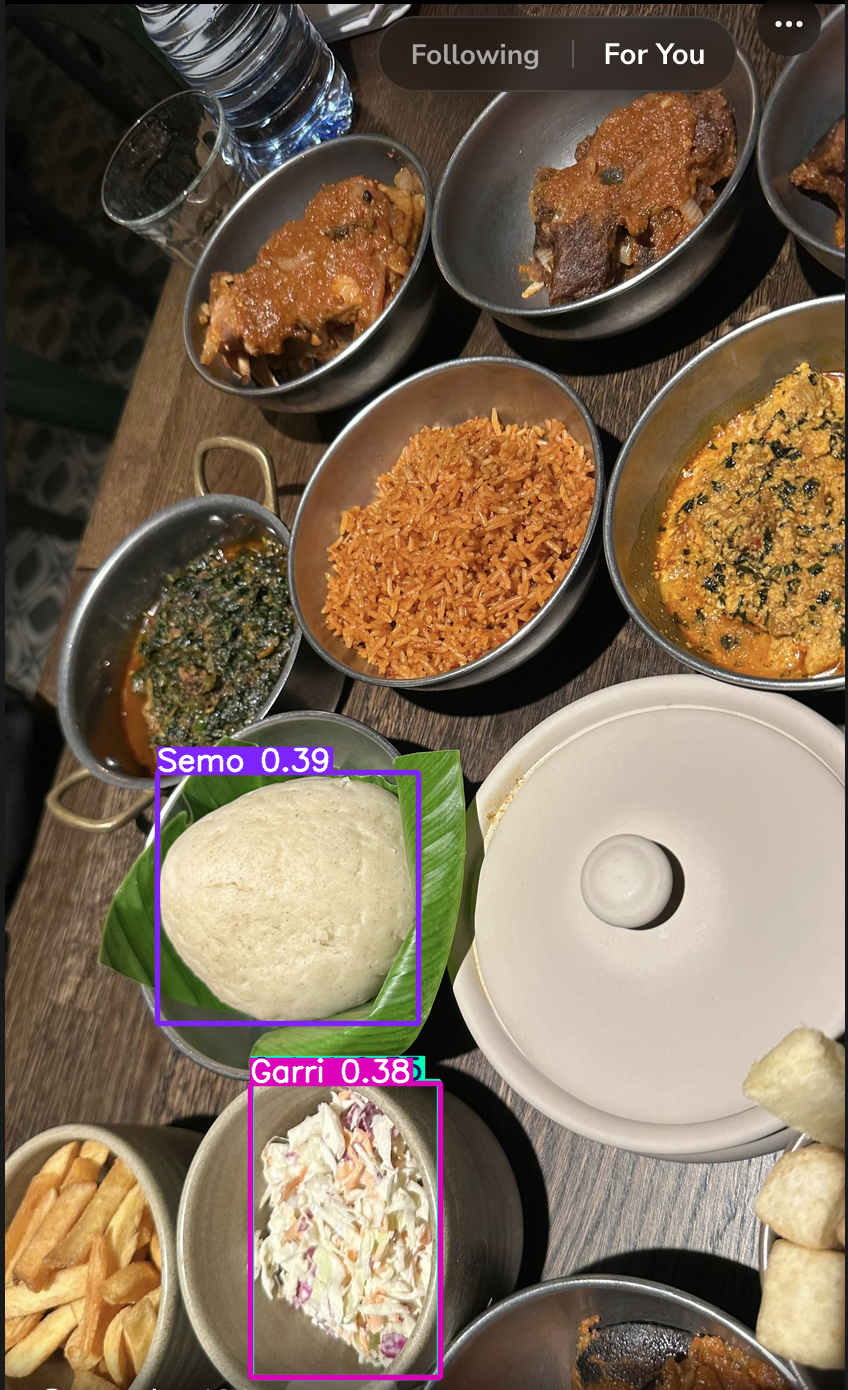


DETECTION RESULTS
Class: Semo | Confidence: 0.393 | Box: (157.1, 773.0, 418.3, 1023.7)
Class: Garri | Confidence: 0.377 | Box: (250.7, 1083.3, 440.3, 1377.0)
Class: Salad | Confidence: 0.347 | Box: (251.6, 1081.4, 439.5, 1377.5)

Total detections: 3


In [30]:
from pathlib import Path
from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt

# Path to your uploaded image
TEST_IMAGE = Path(
    "/kaggle/input/datasets/anselmelvis/test-photo/"
    "Screenshot 2026-11-03 at 7.12.39 PM.png"
)

assert TEST_IMAGE.exists(), f"Image not found: {TEST_IMAGE}"

# Run inference
results = model_exp3.predict(
    source=str(TEST_IMAGE),
    conf=0.25,
    imgsz=640,
    device=0,
    save=True,
    project="/kaggle/working/experiment_3_predictions",
    name="food_image_test"
)

# Get the first prediction result
result = results[0]

# Display annotated image
annotated_image = result.plot()
display(Image.fromarray(annotated_image[:, :, ::-1]))

# Print detection results
print("\nDETECTION RESULTS")
print("=" * 40)

boxes = result.boxes

if boxes is None or len(boxes) == 0:
    print("No food items detected.")
else:
    for box in boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        class_name = model_exp3.names[class_id]

        x1, y1, x2, y2 = box.xyxy[0].tolist()

        print(
            f"Class: {class_name} | "
            f"Confidence: {confidence:.3f} | "
            f"Box: ({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})"
        )

print(f"\nTotal detections: {len(boxes) if boxes is not None else 0}")


image 1/1 /kaggle/input/datasets/anselmelvis/test-photo/Screenshot 2026-11-03 at 7.12.39 PM.png: 640x416 2 Beef-stews, 1 Efo-riro, 1 Ewedu, 1 Fufu, 1 Garri, 1 Salad, 1 Semo, 10.0ms
Speed: 1.9ms preprocess, 10.0ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 416)
LOW-CONFIDENCE DETECTIONS
Semo | Confidence: 0.393 | Box: [157.1, 773.0, 418.3, 1023.7]
Garri | Confidence: 0.377 | Box: [250.7, 1083.3, 440.3, 1377.0]
Salad | Confidence: 0.347 | Box: [251.6, 1081.4, 439.5, 1377.5]
Fufu | Confidence: 0.207 | Box: [155.5, 770.6, 416.7, 1026.3]
Beef-stew | Confidence: 0.186 | Box: [520.5, 89.8, 742.6, 308.0]
Beef-stew | Confidence: 0.153 | Box: [194.2, 172.1, 429.0, 389.2]
Ewedu | Confidence: 0.153 | Box: [118.9, 542.2, 300.0, 776.6]
Efo-riro | Confidence: 0.059 | Box: [119.8, 539.9, 306.6, 774.1]

Total detections: 8


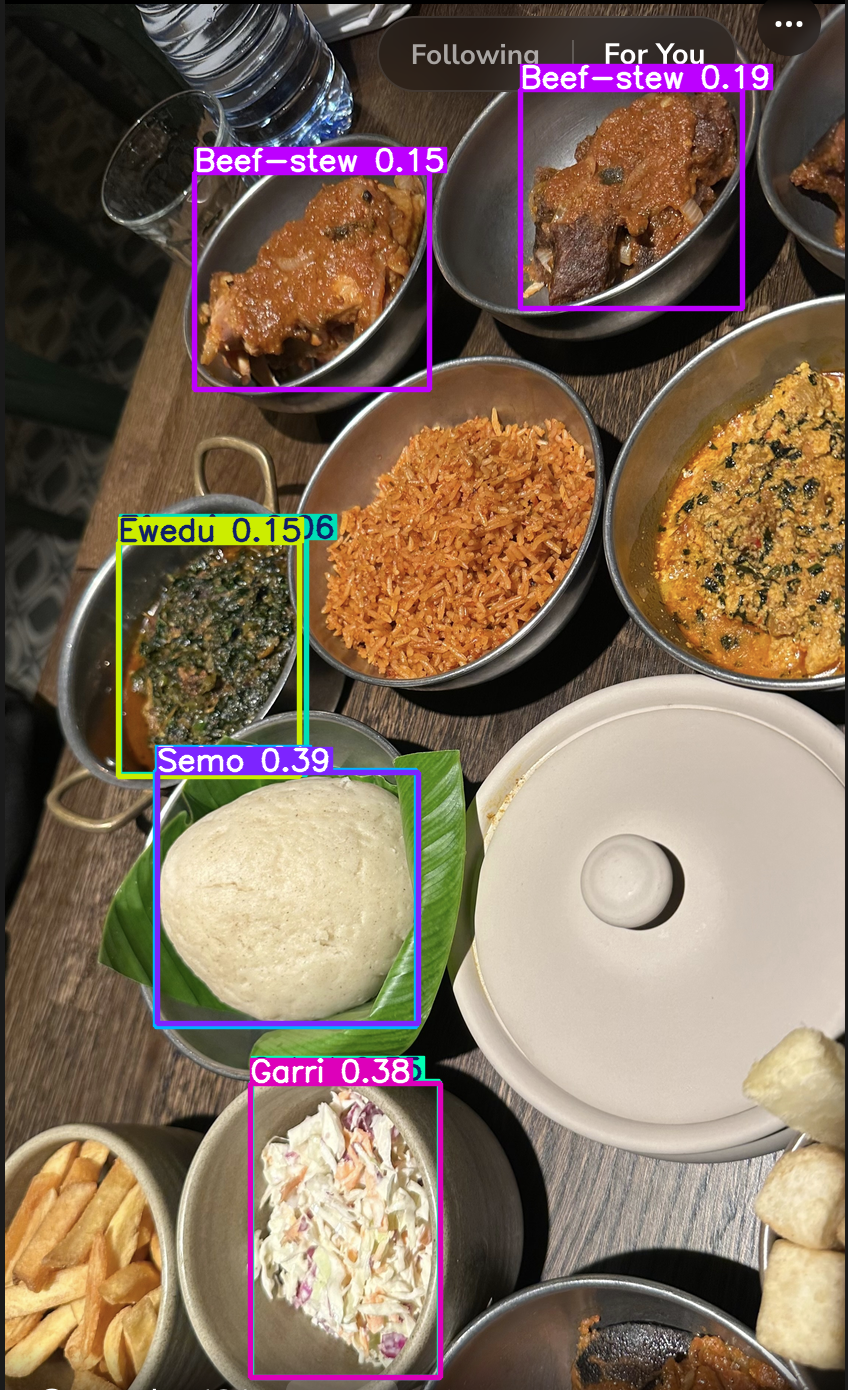

In [33]:
results_low = model_exp3.predict(
    source=TEST_IMAGE,
    conf=0.05,
    imgsz=640,
    device=0,
    save=False
)

result_low = results_low[0]

print("LOW-CONFIDENCE DETECTIONS")
print("=" * 45)

for box in result_low.boxes:
    class_id = int(box.cls.item())
    confidence = float(box.conf.item())
    coordinates = box.xyxy[0].tolist()

    print(
        f"{model_exp3.names[class_id]} | "
        f"Confidence: {confidence:.3f} | "
        f"Box: {[round(x, 1) for x in coordinates]}"
    )

print("\nTotal detections:", len(result_low.boxes))

display(Image.fromarray(result_low.plot()[..., ::-1]))


image 1/1 /kaggle/input/datasets/anselmelvis/test-photo/Screenshot 2026-11-03 at 7.12.39 PM.png: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 589.3ms
Speed: 9.0ms preprocess, 589.3ms inference, 115.5ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to /kaggle/working/experiment_4/sam_segmentation
Number of masks: 5


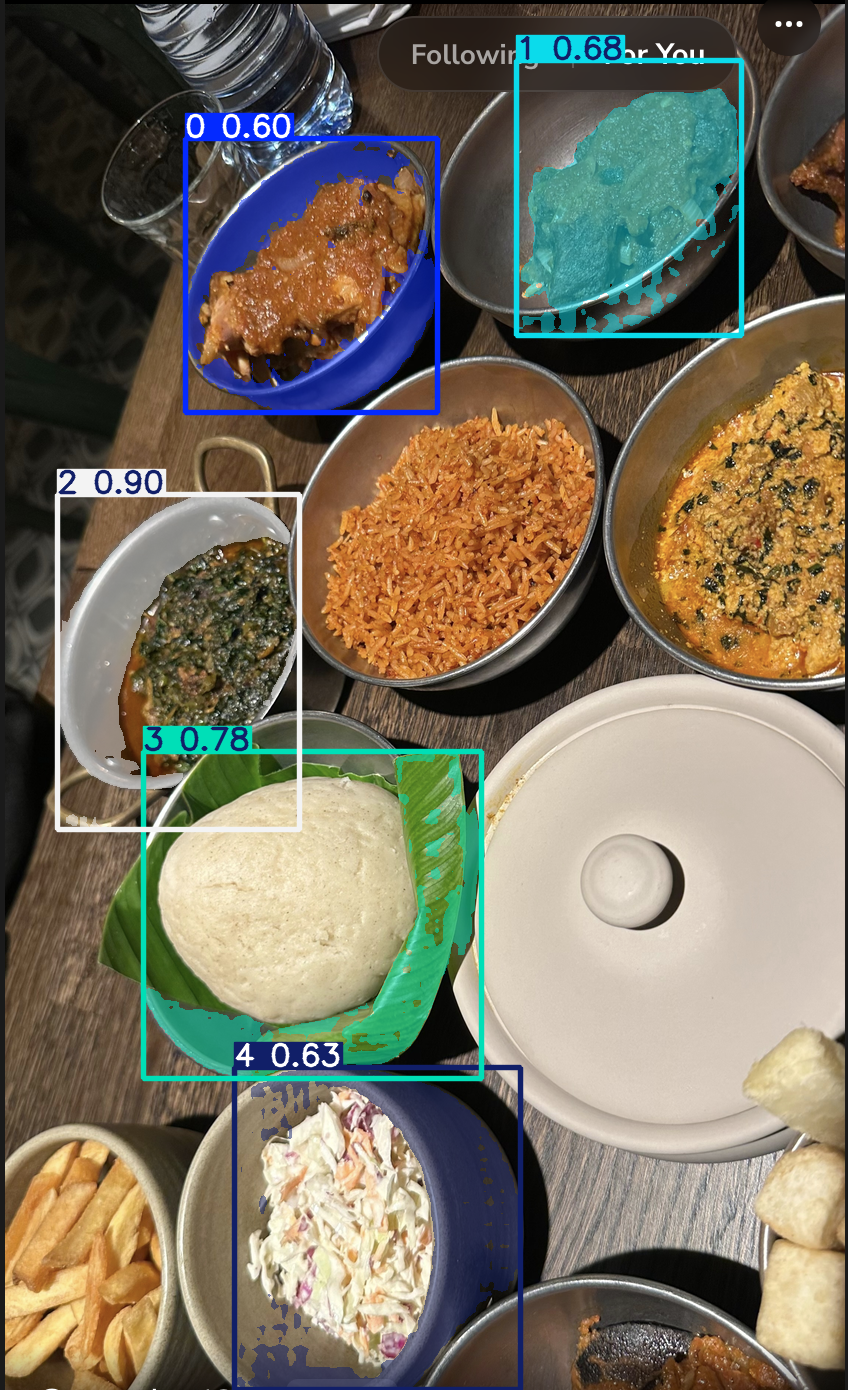

In [36]:
from PIL import Image
from IPython.display import display
from pathlib import Path

TEST_IMAGE = (
    "/kaggle/input/datasets/anselmelvis/"
    "test-photo/"
    "Screenshot 2026-11-03 at 7.12.39 PM.png"
)

FOOD_BOXES = [
    [190, 160, 435, 395],   # Top-left meat dish
    [515, 60, 750, 315],    # Top-centre meat dish
    [55, 495, 315, 800],    # Vegetable soup
    [140, 735, 475, 1085],  # Swallow
    [240, 1065, 475, 1390]  # Coleslaw
]

results_sam = sam_model.predict(
    source=TEST_IMAGE,
    bboxes=FOOD_BOXES,
    device=0,
    save=True,
    project="/kaggle/working/experiment_4",
    name="sam_segmentation",
    exist_ok=True
)

result_sam = results_sam[0]

print("Number of masks:", len(result_sam.masks.data))

display(Image.fromarray(result_sam.plot()[..., ::-1]))

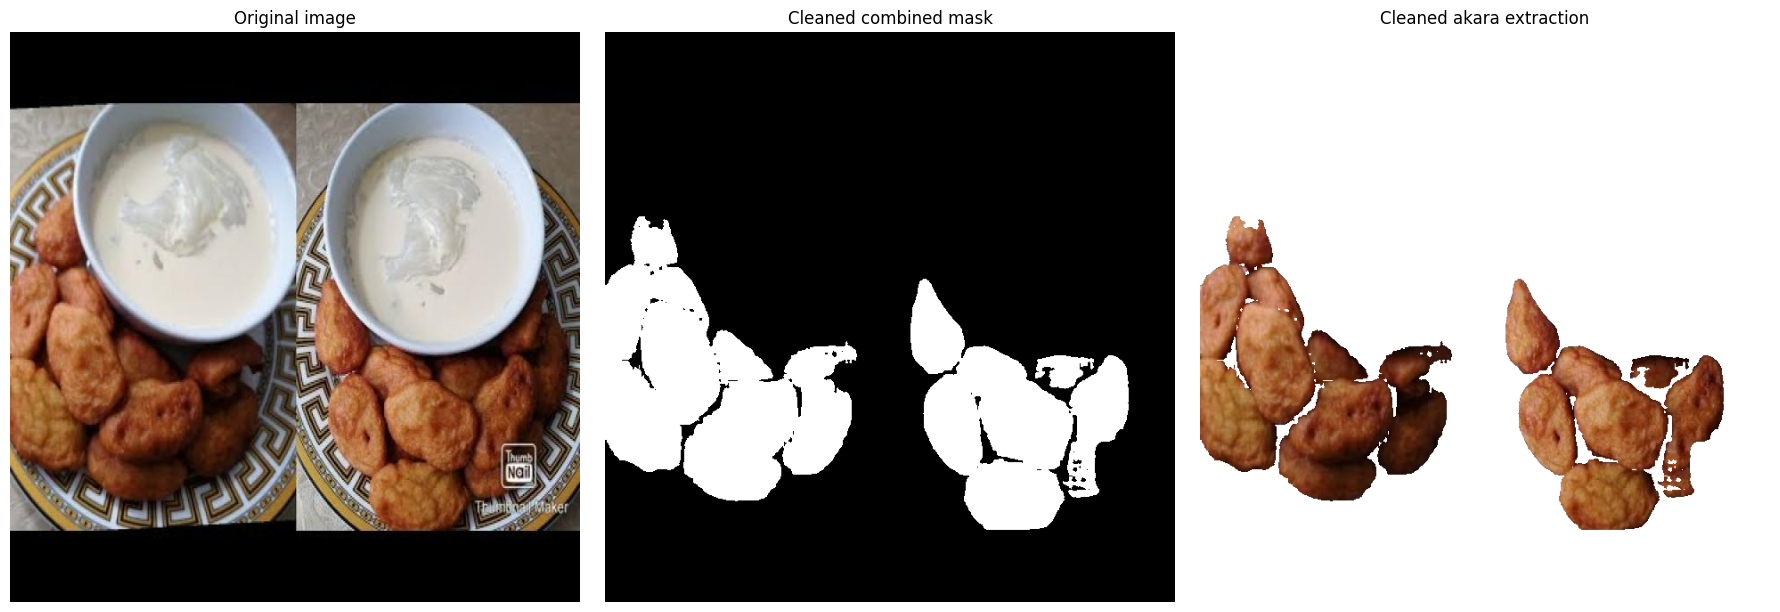

Original foreground pixels: 85333
Cleaned foreground pixels: 84594
Components detected: 50
Clean extraction saved: /kaggle/working/experiment_5/akara/combined_akara_clean_extraction.png


In [87]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/experiment_5/akara")

MASK_PATH = OUTPUT_DIR / "combined_akara_mask.png"
CLEAN_MASK_PATH = OUTPUT_DIR / "combined_akara_clean_mask.png"
CLEAN_EXTRACTION_PATH = OUTPUT_DIR / "combined_akara_clean_extraction.png"

# Load combined mask
combined_mask = np.array(
    Image.open(MASK_PATH).convert("L")
) > 0

# Identify connected components
binary_mask = combined_mask.astype(np.uint8)

num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )
)

# Remove small isolated regions
MIN_AREA = 250

clean_mask = np.zeros_like(binary_mask)

for component_id in range(1, num_labels):
    area = stats[component_id, cv2.CC_STAT_AREA]

    if area >= MIN_AREA:
        clean_mask[labels == component_id] = 1

# Recover the original image
if "source_image" in globals():
    source = source_image
elif "original_image" in globals():
    source = np.array(original_image.convert("RGB"))
elif "image" in globals():
    source = np.array(image.convert("RGB"))
else:
    raise NameError("Original image variable not found.")

# Extract akara
clean_extraction = np.where(
    clean_mask[..., None].astype(bool),
    source,
    255
).astype(np.uint8)

# Save results
Image.fromarray(clean_mask * 255).save(CLEAN_MASK_PATH)
Image.fromarray(clean_extraction).save(CLEAN_EXTRACTION_PATH)

# Compare
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(source)
axes[0].set_title("Original image")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("Cleaned combined mask")

axes[2].imshow(clean_extraction)
axes[2].set_title("Cleaned akara extraction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original foreground pixels:", int(combined_mask.sum()))
print("Cleaned foreground pixels:", int(clean_mask.sum()))
print("Components detected:", num_labels - 1)
print("Clean extraction saved:", CLEAN_EXTRACTION_PATH)